<hr style="height: 2px; background-color: red;">



<h1 style="text-align: justify;">
    Universidad de los Llanos<br><br>
    Facultad de Ciencias Básicas e Ingeniería<br><br>
    Escuela de Ingeniería<br><br>
    Programa de Ingeniería de Sistemas<br><br>
    Curso 1 de Profundización: Teoría de la Computación (603801)<br><br>
    Profesor: Cesar Augusto Diaz Celis - cesar.diaz@unillanos.edu.co<br><br>
    Oficinas: Tercer Piso edificio Albert Einstein (AdaLab) - Segundo Piso Albert Einstein (Laboratorio de Software e Infraestructura Computacional Especializada)) - Primer Piso Leonardo Da Vinci (GITECX)
</h1>

<hr style="height: 2px; background-color: red;">

# <b style="color: #CB0000; font-size:28px;">Proyecto Final Horario — Solución de la instancia pública (Equipo01)</b>

<hr style="height: 2px; background-color: red;">

## <b style="color: #CB0000; font-size:28px;">Datos del equipo</b>

In [1]:
# =============================================================================
# DATOS DEL EQUIPO  (diligenciar; se copian al JSON de entrega)
# =============================================================================
EQUIPO = "Equipo01"                    # número asignado por el profesor (Grupo 1)
INTEGRANTES = [
    {
        "codigo": "160005011",
        "nombre": "Johan Sebastian Forero Agudelo"
    },
    {
        "codigo": "160005004",
        "nombre": "Santiago Barrera Meza"
    },
    {
        "codigo": "160005010",
        "nombre": "Jesus Gregorio Delgado"
    }
]
ALGORITMO = ("Greedy 'más restringido primero' (orden por flexibilidad(); cada bloque va a la franja y salón "
             "factibles de menor costo incremental S1-S6) + recocido simulado con número fijo de iteraciones "
             "sobre horarios siempre factibles; movimientos: mover bloque, intercambiar franjas de bloques "
             "en conflicto, cadena de Kempe entre dos franjas y cambio de salón; costo incremental exacto "
             "con máscaras de bits por (paquete|profesor, día).")

## <b style="color: #CB0000; font-size:28px;">Introducción</b>

**Objetivo:** generar varias soluciones factibles del horario del Programa cambiando la semilla aleatoria, compararlas por su penalización y entregar la mejor en `resultados/solucion_publica.json`.

**Conceptos que se usan:** diccionarios y `defaultdict` para acceso O(1) por id; conjuntos para saber qué recurso está ocupado en qué franja; `Counter` para contar; ordenamiento con clave; un algoritmo codicioso (asignar el mejor candidato bloque por bloque); búsqueda local (mover un bloque si mejora la penalización).

**Restricciones duras (obligatorias):** H1 profesor, H2 salón, H3 paquete, H4 capacidad, H5 disponibilidad, H6 tipo de salón, H7 completitud. **Blandas (se minimizan):** S1 huecos de paquete (peso 2), S2 huecos de profesor, S3 mismo día (peso 3), S4 fuera de preferencia, S5 cambio de salón, S6 franja de baja preferencia.

**Cómo lo resolvimos (Equipo01).** Asignar franjas es colorear el grafo de conflictos de la sección 4.2 del enunciado: cada bloque es un vértice, dos bloques que comparten profesor o paquete son adyacentes y cada franja es un color; a eso se suma escoger salón. Por eso no buscamos el óptimo exacto sino una buena solución con heurísticas:

1. **Greedy:** se ordenan los grupos del más restringido al menos restringido y cada bloque toma la (franja, salón) que no viola H1–H6 y que menos aumenta S1–S6.
2. **Búsqueda local (recocido simulado):** sobre ese horario se prueban movimientos pequeños durante un número fijo de iteraciones. Solo se aceptan los que mantienen las duras en cero, así que el horario nunca deja de ser factible. Un movimiento que empeora P se acepta a veces (más al principio que al final) para no quedarse en el primer óptimo local.
3. Se repite con 10 semillas y se entrega la factible de menor P.

## <b style="color: #CB0000; font-size:28px;">Imports y carga del JSON</b>

In [2]:
# --- Importaciones estándar (no se necesita nada externo salvo pandas para tablas) ---
import json                                  # leer el JSON de la instancia
import random                                # aleatoriedad controlada por semilla
import os                                    # crear la carpeta "resultados"
from collections import defaultdict, Counter # estructuras auxiliares
import time                                  # medir el tiempo total
import statistics                            # media y desviación
import pandas as pd                          # solo para mostrar tablas comparativas
from IPython.display import display          # mostrar DataFrames en el notebook
import graphviz                              # diagramas

# --- Rutas ---
RUTA_INSTANCIA = "instancia_publica.json"
RUTA_SALIDA    = "resultados/solucion_publica.json"
os.makedirs("resultados", exist_ok=True)     # No falla si ya existe

# --- Cargar la instancia completa en un diccionario Python ---
with open(RUTA_INSTANCIA, encoding="utf-8") as f:
    inst = json.load(f)

# --- Diagnóstico rápido para saber que cargó bien ---
print("Instancia:", inst["meta"]["id_instancia"])
print("Grupos:", len(inst["grupos"]),
      "| Bloques:", sum(g["num_bloques"] for g in inst["grupos"]),
      "| Franjas:", len(inst["franjas"]),
      "| Salones:", len(inst["salones"]))

Instancia: UCTP-IS-PUB
Grupos: 80 | Bloques: 180 | Franjas: 40 | Salones: 12


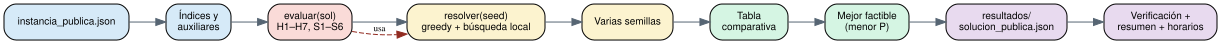

In [3]:
# Flujo de la solución (se dibuja con graphviz)
flujo = graphviz.Digraph("flujo", format="svg")
flujo.attr(rankdir="LR", bgcolor="white", fontname="Helvetica", nodesep="0.25")
N = dict(shape="box", style="rounded,filled", fontname="Helvetica", fontsize="10")
pasos = [("json", "instancia_publica.json", "#D6EAF8"), ("idx", "Índices y\nauxiliares", "#D6EAF8"),
         ("ev", "evaluar(sol)\nH1–H7, S1–S6", "#FADBD8"), ("res", "resolver(seed)\ngreedy + búsqueda local", "#FCF3CF"),
         ("sem", "Varias semillas", "#FCF3CF"), ("tab", "Tabla\ncomparativa", "#D5F5E3"),
         ("mej", "Mejor factible\n(menor P)", "#D5F5E3"), ("out", "resultados/\nsolucion_publica.json", "#E8DAEF"),
         ("ver", "Verificación +\nresumen + horarios", "#E8DAEF")]
for k, t, c in pasos:
    flujo.node(k, t, fillcolor=c, **N)
for a, b in zip([p[0] for p in pasos], [p[0] for p in pasos][1:]):
    flujo.edge(a, b, color="#566573")
flujo.edge("ev", "res", style="dashed", color="#922B21", label=" usa", fontsize="9")
flujo

## <b style="color: #CB0000; font-size:28px;">Índices y funciones auxiliares (independientes de la semilla)</b>

In [4]:
# =============================================================================
# 1) ÍNDICES: id -> objeto
# Sirven para responder "¿cuál es la capacidad de DV-LC1?" en O(1).
# =============================================================================
franja   = {f["id_franja"]: f for f in inst["franjas"]}
salon    = {s["id_salon"]: s  for s in inst["salones"]}
curso    = {c["id_curso"]: c  for c in inst["cursos"]}
grupo    = {g["id_grupo"]: g  for g in inst["grupos"]}
profesor = {p["id_profesor"]: p for p in inst["profesores"]}

# =============================================================================
# 2) DISPONIBILIDAD: (profesor, franja) -> estado
# Regla: lo que NO aparece en la tabla de disponibilidad se asume
# DISPONIBLE. Solo NO_DISPONIBLE bloquea (H5) y PREFERIDA da bonus (S4).
# =============================================================================
disp = {(d["id_profesor"], d["id_franja"]): d["estado"]
        for d in inst["disponibilidad"]}

# =============================================================================
# 3) PAQUETES: grupo -> lista de paquetes a los que pertenece
# Un grupo puede estar en varios paquetes (por ejemplo las electivas).
# Se usa para H3 (dos grupos del mismo paquete no comparten franja)
# y para S1 (huecos por paquete).
# =============================================================================
paquetes_de = defaultdict(list)              # defaultdict evita KeyError
for p in inst["paquetes"]:
    paquetes_de[p["id_grupo"]].append(p["id_paquete"])

# =============================================================================
# 4) SALONES POR TIPO: "LAB_COMPUTO" -> [DV-LC1, ...]
# Se usa en H6 (tipo de salón) y para iterar solo los candidatos válidos.
# =============================================================================
salones_por_tipo = defaultdict(list)
for s in inst["salones"]:
    salones_por_tipo[s["tipo"]].append(s["id_salon"])

# =============================================================================
# 5) PROFESORES CON AL MENOS UNA FRANJA PREFERIDA
# Regla S4: solo se penaliza "fuera de preferencia" si el profesor TIENE
# alguna preferida. Si no tiene ninguna, no se le exige nada.
# =============================================================================
tiene_pref = {p for (p, _), v in disp.items() if v == "PREFERIDA"}

# =============================================================================
# 6) LISTA PLANA DE BLOQUES A ASIGNAR
# Cada grupo aporta `num_bloques` bloques; los numeramos 1..num_bloques.
# Total = 180 en la instancia pública.
# =============================================================================
bloques_base = [(g["id_grupo"], b)
                for g in inst["grupos"]
                for b in range(1, g["num_bloques"] + 1)]
assert len(bloques_base) == 180, "¡La instancia cambió de tamaño!"

# =============================================================================
# 7) FUNCIONES AUXILIARES
# =============================================================================
def disponible(prof, fid):
    """True si el profesor PUEDE dictar en esa franja (H5)."""
    # Si no aparece en el diccionario, se asume DISPONIBLE.
    return disp.get((prof, fid), "DISPONIBLE") != "NO_DISPONIBLE"

def flexibilidad(gid):
    """
    Devuelve una tupla que mide lo 'restringido' que es un grupo.
    Menor tupla = más restringido = hay que asignarlo PRIMERO.

    Componentes:
      1. len(paquetes_de[gid])  -> más paquetes = más conflictos H3.
      2. libres_prof            -> menos franjas disponibles = más difícil.
      3. sal_compat             -> menos salones compatibles = más difícil.
      4. -inscritos             -> más inscritos = menos salones caben.
    """
    g = grupo[gid]
    prof = g["id_profesor"]
    # Cuántas franjas puede usar este profesor
    libres_prof = sum(1 for f in franja if disponible(prof, f))
    c = curso[g["id_curso"]]
    # Cuántos salones son del tipo correcto y tienen capacidad suficiente
    sal_compat = sum(1 for s in inst["salones"]
                     if s["tipo"] == c["tipo_salon"]
                     and s["capacidad"] >= g["inscritos"])
    return (len(paquetes_de[gid]), libres_prof, sal_compat, -g["inscritos"])

## <b style="color: #CB0000; font-size:28px;">Evaluación exacta</b>

Implemente `evaluar(sol)` siguiendo **exactamente** las reglas de conteo de la sección 6 del enunciado. La celda siguiente contiene pruebas con los valores correctos: si alguna falla, la penalización que declare en el JSON no coincidirá con la del evaluador oficial (criterio F2 de la rúbrica).

In [5]:
# =============================================================================
# CONSTANTES QUE USA evaluar()
# =============================================================================
# Pesos de las blandas: la clave del JSON es "S1_huecos_paquete" -> nos quedamos con "S1".
PESOS = {k.split("_")[0]: v for k, v in inst["meta"]["pesos_restricciones_blandas"].items()}
# Conjunto de los 180 pares (id_grupo, num_bloque) que deben aparecer en la solución (H7).
REQUERIDOS = set(bloques_base)


def huecos(posiciones):
    """huecos(A) = max A − min A + 1 − |A|, con A = posiciones orden_dia DISTINTAS ocupadas en un día."""
    A = set(posiciones)
    return max(A) - min(A) + 1 - len(A) if A else 0


def _es_entero(v):
    """En Python bool es subclase de int; True no debe aceptarse como num_bloque."""
    return isinstance(v, int) and not isinstance(v, bool)


def evaluar(sol):
    """
    Calcula H1–H7 (duras) y S1–S6 (blandas) de una solución.

    Parámetro:
      sol : lista de dicts {"id_grupo", "num_bloque", "id_franja", "id_salon"}
    Devuelve:
      H : Counter con H1..H7 (0 = restricción cumplida)
      S : Counter con S1..S6 (valor crudo, sin pesos)
      P : penalización ponderada = suma(pesos[k] * S[k])
    Reglas exactas de conteo: sección 6 del enunciado.
    """
    H = Counter({k: 0 for k in ["H1", "H2", "H3", "H4", "H5", "H6", "H7"]})
    S = Counter({k: 0 for k in ["S1", "S2", "S3", "S4", "S5", "S6"]})

    # ---------------------------------------------------------------------
    # H7 — formato y completitud. Inválidas y repetidas se cuentan y se DESCARTAN.
    # ---------------------------------------------------------------------
    validas, vistos = [], set()
    for a in sol:
        ok = isinstance(a, dict)
        if ok:
            gid, nb = a.get("id_grupo"), a.get("num_bloque")
            fid, sid = a.get("id_franja"), a.get("id_salon")
            ok = (isinstance(gid, str) and _es_entero(nb) and isinstance(fid, str) and isinstance(sid, str)
                  and gid in grupo and fid in franja and sid in salon
                  and 1 <= nb <= grupo[gid]["num_bloques"])
        if not ok:                       # campo faltante, tipo incorrecto, id inexistente o fuera de rango
            H["H7"] += 1
            continue
        if (gid, nb) in vistos:          # bloque repetido: cuenta 1 y se ignora la copia
            H["H7"] += 1
            continue
        vistos.add((gid, nb))
        validas.append(a)
    H["H7"] += len(REQUERIDOS - vistos)  # bloques requeridos ausentes

    # ---------------------------------------------------------------------
    # Recorrido único de las asignaciones válidas: H4, H5, H6, S4, S6 por bloque
    # y contadores para H1, H2, H3, S1, S2, S3, S5.
    # ---------------------------------------------------------------------
    uso_prof, uso_salon, uso_paq = Counter(), Counter(), Counter()
    pos_paq, pos_prof = defaultdict(set), defaultdict(set)   # (paquete|profesor, día) -> {orden_dia}
    dia_grupo = Counter()                                    # (grupo, día) -> bloques
    salones_grupo = defaultdict(set)                         # grupo -> salones usados
    for a in validas:
        g = grupo[a["id_grupo"]]
        f = franja[a["id_franja"]]
        s = salon[a["id_salon"]]
        prof, fid, dia, pos = g["id_profesor"], f["id_franja"], f["dia"], f["orden_dia"]

        H["H4"] += s["capacidad"] < g["inscritos"]
        H["H5"] += disp.get((prof, fid)) == "NO_DISPONIBLE"
        H["H6"] += s["tipo"] != curso[g["id_curso"]]["tipo_salon"]
        S["S4"] += prof in tiene_pref and disp.get((prof, fid)) != "PREFERIDA"
        S["S6"] += f["baja_preferencia"]

        uso_prof[(prof, fid)] += 1
        uso_salon[(s["id_salon"], fid)] += 1
        for paq in paquetes_de[g["id_grupo"]]:
            uso_paq[(paq, fid)] += 1
            pos_paq[(paq, dia)].add(pos)
        pos_prof[(prof, dia)].add(pos)
        dia_grupo[(g["id_grupo"], dia)] += 1
        salones_grupo[g["id_grupo"]].add(s["id_salon"])

    # H1, H2, H3: por cada (recurso, franja) con c > 1 bloques se suma c − 1.
    H["H1"] += sum(c - 1 for c in uso_prof.values() if c > 1)
    H["H2"] += sum(c - 1 for c in uso_salon.values() if c > 1)
    H["H3"] += sum(c - 1 for c in uso_paq.values() if c > 1)

    # Blandas que dependen de varios bloques.
    S["S1"] += sum(huecos(A) for A in pos_paq.values())
    S["S2"] += sum(huecos(A) for A in pos_prof.values())
    S["S3"] += sum(max(0, c - 1) for c in dia_grupo.values())
    S["S5"] += sum(len(u) - 1 for u in salones_grupo.values())

    H = Counter({k: int(v) for k, v in H.items()})
    S = Counter({k: int(v) for k, v in S.items()})
    P = sum(PESOS[k] * S[k] for k in ["S1", "S2", "S3", "S4", "S5", "S6"])
    return H, S, P


def es_factible(H):
    """True si TODAS las duras valen 0."""
    return all(H.get(k, 0) == 0 for k in ["H1", "H2", "H3", "H4", "H5", "H6", "H7"])

In [6]:
# =============================================================================
# PRUEBAS MÍNIMAS DE evaluar()  — deben pasar TODAS antes de continuar.
# Son soluciones PARCIALES, por eso H7 cuenta los bloques que faltan.
# =============================================================================
A = lambda g, b, f, s: {"id_grupo": g, "num_bloque": b, "id_franja": f, "id_salon": s}
pruebas = {
    "T1 vacía (faltan los 180 bloques)": ([], {"H7": 180}, 0),
    "T2 choque de profesor (P11 en MA_10)": ([A("603102-G1", 1, "MA_10", "AE-201"), A("603102-G2", 1, "MA_10", "AE-202")],
                                             {"H1": 1, "H7": 178}, None),
    "T3 capacidad y tipo (laboratorio en aula de 30)": ([A("603101-G1", 1, "JU_08", "AE-204")], {"H4": 1, "H6": 1, "H7": 179}, None),
    "T4 hueco de paquete SEM5 el lunes": ([A("603502-G1", 1, "LU_06", "AE-201"), A("603503-G1", 1, "LU_12", "AE-202")],
                                          {"S1": 2, "S6": 1}, 6),
    "T5 mismo grupo dos veces el martes": ([A("603502-G1", 1, "MA_14", "AE-201"), A("603502-G1", 2, "MA_16", "AE-201")],
                                           {"S3": 1, "S4": 2}, 5),
    "T6 repetido, fuera de rango e inexistente": ([A("603502-G1", 1, "LU_08", "AE-201"), A("603502-G1", 1, "MA_08", "AE-201"),
                                                   A("603502-G1", 3, "MA_08", "AE-201"), A("XXX", 1, "LU_08", "AE-201")],
                                                  {"H7": 182}, None),
}
fallas = 0
for nombre, (sol_p, esperado, P_esp) in pruebas.items():
    H_t, S_t, P_t = evaluar(sol_p)
    obtenido = {k: (H_t.get(k, 0) if k.startswith("H") else S_t.get(k, 0)) for k in esperado}
    ok = obtenido == esperado and (P_esp is None or P_t == P_esp)
    fallas += not ok
    print(f"[{'OK' if ok else 'FALLA'}] {nombre}: esperado {esperado}" + (f", P={P_esp}" if P_esp is not None else "")
          + ("" if ok else f" | obtenido {obtenido}, P={P_t}"))
assert fallas == 0, f"{fallas} prueba(s) fallaron: revise evaluar() con la sección 6 del enunciado."

[OK] T1 vacía (faltan los 180 bloques): esperado {'H7': 180}, P=0
[OK] T2 choque de profesor (P11 en MA_10): esperado {'H1': 1, 'H7': 178}
[OK] T3 capacidad y tipo (laboratorio en aula de 30): esperado {'H4': 1, 'H6': 1, 'H7': 179}
[OK] T4 hueco de paquete SEM5 el lunes: esperado {'S1': 2, 'S6': 1}, P=6
[OK] T5 mismo grupo dos veces el martes: esperado {'S3': 1, 'S4': 2}, P=5
[OK] T6 repetido, fuera de rango e inexistente: esperado {'H7': 182}


## <b style="color: #CB0000; font-size:28px;">Pipeline por semilla (greedy + búsqueda local)</b>

<h3 style="text-align: justify;">
La celda siguiente prepara, una sola vez, versiones con índices enteros de los datos que más consulta el algoritmo. La celda de <code>resolver</code> contiene las dos fases.
</h3>

| Decisión | Qué hicimos | Por qué |
|---|---|---|
| Orden del greedy | `restriccion(gid)`: igual a `flexibilidad()` de la plantilla pero con **más paquetes primero** | `flexibilidad()` devuelve `len(paquetes)` y al ordenar de menor a mayor deja las 6 electivas (9 paquetes cada una) para el final, cuando ya casi no les quedan franjas. La Respuesta 4 mide el efecto. |
| Candidatos del greedy | Solo franjas donde el profesor está disponible (`G_FRA`) y salones del tipo y capacidad del grupo (`G_SAL`) | Así H4, H5 y H6 se cumplen por construcción; `puede_ir` solo revisa H1, H2 y H3. |
| Costo incremental | Por cada (paquete, día) y (profesor, día) se guarda una máscara de 7 bits con las posiciones ocupadas; `HUECOS_MASK[m]` da los huecos ya calculados | Un movimiento solo cambia uno o dos días de unos pocos paquetes y profesores. Recalcular esa zona, antes y después, da el delta exacto de P sin llamar a `evaluar` (comprobado con un `assert` al final de cada corrida). |
| Movimientos | a) mover un bloque, b) intercambiar franjas con un bloque en conflicto, c) cadena de Kempe entre dos franjas, d) cambiar de salón | Con H3 tan cargado (las electivas comparten 9 paquetes), mover un bloque suele chocar con algo. La cadena de Kempe intercambia dos "colores" en todo un componente del grafo de conflictos y así llega a horarios que un solo movimiento no alcanza. |
| Aceptación | Recocido simulado: acepta si el delta es ≤ 0, o con probabilidad e<sup>−delta/T</sup>; T baja de 2.0 a 0.05 | Con T alta se puede empeorar para salir de óptimos locales; al final solo se aceptan mejoras. Se guarda la mejor solución vista. |
| Reproducibilidad | `random.Random(seed)` para todo lo aleatorio, parada por número de iteraciones y recorrido de listas (nunca de `set` de textos) donde importa el orden | El orden de un `set` de cadenas cambia entre ejecuciones de Python; si decidiera algo, la misma semilla daría otro horario. |

In [7]:
import math                                  # exp() del criterio de aceptación del recocido

# =============================================================================
# ESTRUCTURAS ENTERAS PARA EL SOLUCIONADOR (independientes de la semilla)
# En la búsqueda local se evalúan cientos de miles de movimientos; trabajar con
# índices enteros y listas en lugar de cadenas y dicts lo hace varias veces más rápido.
# =============================================================================
F_IDS = list(franja)                                   # índice f -> "LU_06", ...
R_IDS = list(salon)                                    # índice r -> "AE-201", ...
G_IDS = list(grupo)                                    # índice g -> "603101-G1", ...
PROF_IDS = list(profesor)
PAQ_IDS = list(dict.fromkeys(p["id_paquete"] for p in inst["paquetes"]))
DIAS = list(dict.fromkeys(f["dia"] for f in inst["franjas"]))   # LUNES ... SABADO

F_DIA = [DIAS.index(franja[f]["dia"]) for f in F_IDS]           # día de cada franja
F_BIT = [1 << franja[f]["orden_dia"] for f in F_IDS]            # posición del día como bit

# Huecos de un día guardado como máscara de bits (bit p = posición orden_dia p ocupada).
# Se precalcula para las 2^7 máscaras posibles: consultar huecos cuesta O(1).
HUECOS_MASK = [huecos([p for p in range(7) if m >> p & 1]) for m in range(1 << 7)]

G_PROF = [PROF_IDS.index(grupo[g]["id_profesor"]) for g in G_IDS]
G_PAQ = [[PAQ_IDS.index(k) for k in paquetes_de[g]] for g in G_IDS]
# Salones válidos para el grupo: tipo exigido por el curso (H6) y capacidad suficiente (H4).
G_SAL = [[r for r, sid in enumerate(R_IDS)
          if salon[sid]["tipo"] == curso[grupo[g]["id_curso"]]["tipo_salon"]
          and salon[sid]["capacidad"] >= grupo[g]["inscritos"]] for g in G_IDS]
# Franjas en las que el profesor del grupo puede dictar (H5).
G_FRA = [[f for f, fid in enumerate(F_IDS) if disponible(grupo[g]["id_profesor"], fid)] for g in G_IDS]
G_FRA_OK = [set(x) for x in G_FRA]
# Costo que depende solo de (grupo, franja): S4 (fuera de preferida) + S6 (baja preferencia).
COSTO_FIJO = [[int(grupo[g]["id_profesor"] in tiene_pref and disp.get((grupo[g]["id_profesor"], fid)) != "PREFERIDA")
               + int(franja[fid]["baja_preferencia"]) for fid in F_IDS] for g in G_IDS]

# Franjas "gratis" para el grupo (sin costo S4 ni S6): destinos preferidos en la búsqueda local.
G_FRA_BUENAS = [[f for f in G_FRA[g] if COSTO_FIJO[g][f] == 0] for g in range(len(G_IDS))]

GI = {g: i for i, g in enumerate(G_IDS)}
B = len(bloques_base)
B_G = [GI[gid] for gid, _ in bloques_base]             # bloque i -> índice de su grupo
BLOQUES_DE = [[i for i in range(B) if B_G[i] == g] for g in range(len(G_IDS))]
# Vecinos de un bloque: los que comparten paquete o profesor (con ellos chocaría; son
# los mejores candidatos para intercambiar franjas en la búsqueda local).
VECINOS = [[j for j in range(B) if j != i and B_G[j] != B_G[i] and
            (G_PROF[B_G[j]] == G_PROF[B_G[i]] or set(G_PAQ[B_G[j]]) & set(G_PAQ[B_G[i]]))]
           for i in range(B)]
FLEX = {g: flexibilidad(g) for g in G_IDS}              # clave de la plantilla (tal cual)


def restriccion(gid):
    """
    Clave "más restringido primero" que usa nuestro greedy. Igual a flexibilidad() salvo el primer
    componente: flexibilidad() devuelve len(paquetes) y al ordenar de menor a mayor deja de ÚLTIMOS a
    los grupos con más paquetes (las electivas, que están en 9), aunque su docstring dice que más
    paquetes = más conflictos. Aquí se niega para que los grupos con más paquetes vayan PRIMERO.
    """
    npaq, libres_prof, sal_compat, menos_inscritos = flexibilidad(gid)
    return (-npaq, libres_prof, sal_compat, menos_inscritos)


RESTRICCION = {g: restriccion(g) for g in G_IDS}

print(f"Bloques={B}  franjas={len(F_IDS)}  salones={len(R_IDS)}  paquetes={len(PAQ_IDS)}  profesores={len(PROF_IDS)}")
print("Salones compatibles por grupo (mín/máx):", min(map(len, G_SAL)), "/", max(map(len, G_SAL)),
      "| franjas disponibles por grupo (mín/máx):", min(map(len, G_FRA)), "/", max(map(len, G_FRA)))

Bloques=180  franjas=40  salones=12  paquetes=20  profesores=30
Salones compatibles por grupo (mín/máx): 1 / 5 | franjas disponibles por grupo (mín/máx): 23 / 38


In [8]:
def resolver(seed, iteraciones_local=15000, orden_greedy="paquetes"):
    """
    Construye un horario para una semilla dada.
    Devuelve un dict con las claves: seed, factible, P, H, S, sol (lista de asignaciones), atascado

      - rng = random.Random(seed) para TODA decisión aleatoria (la semilla reproduce la solución).
      - Fase 1, constructiva: grupos del más restringido al menos restringido, empates al azar.
          orden_greedy="paquetes"  : clave restriccion() (más paquetes primero) -> la que se usa;
          orden_greedy="plantilla" : clave flexibilidad() tal como viene en la plantilla;
          orden_greedy="azar"      : grupos barajados (solo para el experimento de la Pregunta 4).
        Cada bloque va a la (franja, salón) que cumple H1–H6 con menor aumento de S1–S6.
      - Fase 2, mejora: recocido simulado con exactamente `iteraciones_local` iteraciones.
        Solo se aceptan movimientos que mantienen H1–H6 en cero (el horario siempre es factible).
      - Evaluación final con evaluar(sol).
    """
    rng = random.Random(seed)
    nG, nP, nK, nF, nR = len(G_IDS), len(PROF_IDS), len(PAQ_IDS), len(F_IDS), len(R_IDS)
    nD = len(DIAS)

    # -------------------------------------------------------------------------
    # 1) ESTADO DE OCUPACIÓN. occ_*[x][f] = bloque que ocupa el recurso x en la franja f (-1 = libre).
    #    m_paq / m_prof: máscara de posiciones ocupadas por día (para S1 y S2).
    #    dia_g: bloques del grupo por día (S3).  sal_g / nsal: salones usados por grupo (S5).
    # -------------------------------------------------------------------------
    fr, rm = [-1] * B, [-1] * B
    occ_prof = [[-1] * nF for _ in range(nP)]
    occ_sal = [[-1] * nF for _ in range(nR)]
    occ_paq = [[-1] * nF for _ in range(nK)]
    m_paq = [[0] * nD for _ in range(nK)]
    m_prof = [[0] * nD for _ in range(nP)]
    dia_g = [[0] * nD for _ in range(nG)]
    sal_g = [[0] * nR for _ in range(nG)]
    nsal = [0] * nG

    # -------------------------------------------------------------------------
    # 2) puede_ir / asignar / desasignar
    # -------------------------------------------------------------------------
    def puede_ir(i, f, r):
        """H1 profesor, H2 salón y H3 paquetes libres en f (H4–H6 ya se garantizan con G_SAL y G_FRA)."""
        g = B_G[i]
        if occ_sal[r][f] != -1 or occ_prof[G_PROF[g]][f] != -1:
            return False
        for k in G_PAQ[g]:
            if occ_paq[k][f] != -1:
                return False
        return True

    def asignar(i, f, r):
        g, p, d, bit = B_G[i], G_PROF[B_G[i]], F_DIA[f], F_BIT[f]
        fr[i], rm[i] = f, r
        occ_prof[p][f] = i
        occ_sal[r][f] = i
        for k in G_PAQ[g]:
            occ_paq[k][f] = i
            m_paq[k][d] |= bit
        m_prof[p][d] |= bit
        dia_g[g][d] += 1
        sal_g[g][r] += 1
        if sal_g[g][r] == 1:
            nsal[g] += 1

    def desasignar(i):
        f, r = fr[i], rm[i]
        g, p, d, bit = B_G[i], G_PROF[B_G[i]], F_DIA[f], F_BIT[f]
        occ_prof[p][f] = -1
        occ_sal[r][f] = -1
        for k in G_PAQ[g]:
            occ_paq[k][f] = -1
            m_paq[k][d] &= ~bit
        m_prof[p][d] &= ~bit
        dia_g[g][d] -= 1
        sal_g[g][r] -= 1
        if sal_g[g][r] == 0:
            nsal[g] -= 1
        fr[i], rm[i] = -1, -1

    # -------------------------------------------------------------------------
    # 3) COSTO LOCAL: penalización exacta de S1, S2, S3 y S5 restringida a los
    #    (paquete, día), (profesor, día), (grupo, día) y grupos que toca un cambio.
    #    Como el resto del horario no cambia, (después − antes) es el delta exacto de P.
    # -------------------------------------------------------------------------
    def zona(bloques_dias):
        """bloques_dias: lista de (bloque, día). Devuelve las claves afectadas."""
        kd, pd_, gd, gs = set(), set(), set(), set()
        for i, d in bloques_dias:
            g = B_G[i]
            for k in G_PAQ[g]:
                kd.add((k, d))
            pd_.add((G_PROF[g], d))
            gd.add((g, d))
            gs.add(g)
        return kd, pd_, gd, gs

    def costo_local(z):
        kd, pd_, gd, gs = z
        c = 0
        for k, d in kd:
            c += 2 * HUECOS_MASK[m_paq[k][d]]          # S1, peso 2
        for p, d in pd_:
            c += HUECOS_MASK[m_prof[p][d]]             # S2, peso 1
        for g, d in gd:
            if dia_g[g][d] > 1:
                c += 3 * (dia_g[g][d] - 1)             # S3, peso 3
        for g in gs:
            if nsal[g] > 1:
                c += nsal[g] - 1                       # S5, peso 1
        return c

    # -------------------------------------------------------------------------
    # 4) FASE CONSTRUCTIVA (greedy, más restringido primero)
    # -------------------------------------------------------------------------
    if orden_greedy == "azar":
        orden = list(range(nG))
        rng.shuffle(orden)
    else:
        clave = RESTRICCION if orden_greedy == "paquetes" else FLEX
        orden = sorted(range(nG), key=lambda g: (clave[G_IDS[g]], rng.random()))
    for g in orden:
        for i in BLOQUES_DE[g]:
            mejor_c, mejor_fr = None, None
            for f in G_FRA[g]:
                z = zona([(i, F_DIA[f])])
                antes = costo_local(z)
                for r in G_SAL[g]:
                    if not puede_ir(i, f, r):
                        continue
                    asignar(i, f, r)
                    c = (costo_local(z) - antes + COSTO_FIJO[g][f], rng.random())
                    desasignar(i)
                    if mejor_c is None or c < mejor_c:
                        mejor_c, mejor_fr = c, (f, r)
            if mejor_fr is None:                       # ningún (franja, salón) cumple H1–H6
                sol = [{"id_grupo": G_IDS[B_G[j]], "num_bloque": bloques_base[j][1],
                        "id_franja": F_IDS[fr[j]], "id_salon": R_IDS[rm[j]]} for j in range(B) if fr[j] >= 0]
                H, S, P = evaluar(sol)
                return {"seed": seed, "factible": False, "P": P, "H": dict(H), "S": dict(S),
                        "sol": sol, "atascado": bloques_base[i], "P_greedy": None}
            asignar(i, *mejor_fr)

    def a_lista(frs, rms):
        return [{"id_grupo": bloques_base[i][0], "num_bloque": bloques_base[i][1],
                 "id_franja": F_IDS[frs[i]], "id_salon": R_IDS[rms[i]]} for i in range(B)]

    P_actual = evaluar(a_lista(fr, rm))[2]
    P_greedy = P_actual

    # -------------------------------------------------------------------------
    # 5) BÚSQUEDA LOCAL: recocido simulado con un número FIJO de iteraciones.
    #    Movimientos:
    #      a) mover un bloque a otra franja (salón: preferentemente uno que ya use su grupo, por S5);
    #      b) intercambiar las franjas de dos bloques que chocan (comparten paquete o profesor);
    #      c) cadena de Kempe entre dos franjas (con salones fijos o repartiendo salones libres);
    #      d) cambiar solo el salón de un bloque.
    #    T baja geométricamente de T0 a TF; se guarda la mejor solución vista.
    #    Se acepta si delta <= 0, o con probabilidad exp(-delta/T) (permite salir de óptimos locales).
    # -------------------------------------------------------------------------
    T0, TF = 2.0, 0.05
    enfriamiento = (TF / T0) ** (1.0 / max(1, iteraciones_local))
    T = T0
    mejor_P, mejor_fr, mejor_rm = P_actual, fr[:], rm[:]

    def intentar(cambios):
        """cambios: [(bloque, franja_nueva, salón_nuevo), ...]. Devuelve el delta de P si se aceptó, None si no."""
        viejos = [(i, fr[i], rm[i]) for i, _, _ in cambios]
        z = zona([(i, F_DIA[fr[i]]) for i, _, _ in cambios] + [(i, F_DIA[f]) for i, f, _ in cambios])
        antes = costo_local(z) + sum(COSTO_FIJO[B_G[i]][fr[i]] for i, _, _ in cambios)
        for i, _, _ in cambios:
            desasignar(i)
        puestos = 0
        for i, f, r in cambios:
            if not puede_ir(i, f, r):
                break
            asignar(i, f, r)
            puestos += 1
        if puestos == len(cambios):
            delta = costo_local(z) + sum(COSTO_FIJO[B_G[i]][f] for i, f, _ in cambios) - antes
            if delta <= 0 or rng.random() < math.exp(-delta / T):
                return delta
            puestos = len(cambios)
        for i, _, _ in cambios[:puestos]:              # deshacer
            desasignar(i)
        for i, f, r in viejos:
            asignar(i, f, r)
        return None

    def cadena_kempe(i, f2, salon_fijo):
        """
        Cadena de Kempe entre la franja actual de i (f1) y f2: i pasa a f2; todo bloque que en f2
        choca con él (mismo profesor o paquete; y mismo salón si salon_fijo) pasa a f1, lo que a su
        vez puede expulsar bloques de f1 hacia f2, y así hasta cerrar la cadena.
        Es el intercambio clásico de dos colores en el grafo de conflictos.
          salon_fijo=True : cada bloque conserva su salón (el salón también genera choques).
          salon_fijo=False: la cadena solo sigue profesor/paquete y luego se reparten salones libres.
        """
        f1 = fr[i]
        destino = {i: f2}
        pendientes = [i]
        while pendientes:
            b = pendientes.pop()
            fd, gb = destino[b], B_G[b]
            if fd not in G_FRA_OK[gb]:                 # el profesor no puede en esa franja (H5)
                return None
            choques = [occ_prof[G_PROF[gb]][fd]] + [occ_paq[k][fd] for k in G_PAQ[gb]]
            if salon_fijo:
                choques.append(occ_sal[rm[b]][fd])
            for x in choques:
                if x != -1 and x not in destino:
                    destino[x] = f1 if fd == f2 else f2
                    pendientes.append(x)
            if len(destino) > 12:                      # cadenas muy largas casi nunca mejoran
                return None
        if salon_fijo:
            return [(b, fd, rm[b]) for b, fd in destino.items()]

        # Reparto de salones: en cada franja quedan libres los salones vacíos y los que dejan
        # los bloques de la cadena que salen de ella. Primero se intenta conservar el salón propio,
        # luego uno que ya use el grupo (S5) y por último cualquiera compatible.
        nuevo_salon = {}
        for fd in (f1, f2):
            llegan = [b for b, f in destino.items() if f == fd]
            libres = {r for r in range(nR) if occ_sal[r][fd] == -1 or occ_sal[r][fd] in destino}
            for b in llegan:
                if rm[b] in libres:
                    nuevo_salon[b] = rm[b]
                    libres.discard(rm[b])
            for b in llegan:
                if b in nuevo_salon:
                    continue
                gb = B_G[b]
                cand = [r for r in G_SAL[gb] if r in libres]
                if not cand:
                    return None
                usados = [r for r in cand if sal_g[gb][r] > 0]
                r = usados[0] if usados else cand[0]
                nuevo_salon[b] = r
                libres.discard(r)
        return [(b, fd, nuevo_salon[b]) for b, fd in destino.items()]

    for _ in range(iteraciones_local):
        T *= enfriamiento
        i = rng.randrange(B)
        g = B_G[i]
        x = rng.random()
        if x < 0.35:                                   # a) mover
            f = rng.choice(G_FRA[g])
            if f == fr[i]:
                continue
            if rng.random() < 0.8:
                r = rm[rng.choice(BLOQUES_DE[g])]      # salón de un bloque hermano (o el propio)
            else:
                r = rng.choice(G_SAL[g])
            cambios = [(i, f, r)]
        elif x < 0.60:                                 # b) intercambiar franjas
            j = rng.choice(VECINOS[i]) if (VECINOS[i] and rng.random() < 0.7) else rng.randrange(B)
            gj = B_G[j]
            if j == i or fr[j] == fr[i] or fr[j] not in G_FRA_OK[g] or fr[i] not in G_FRA_OK[gj]:
                continue
            cambios = [(i, fr[j], rm[i]), (j, fr[i], rm[j])]
        elif x < 0.90:                                 # c) cadena de Kempe hacia otra franja
            f = rng.choice(G_FRA_BUENAS[g]) if (G_FRA_BUENAS[g] and rng.random() < 0.5) else rng.choice(G_FRA[g])
            if f == fr[i]:
                continue
            cambios = cadena_kempe(i, f, rng.random() < 0.5)
            if cambios is None:
                continue
        else:                                          # d) cambiar salón
            r = rng.choice(G_SAL[g])
            if r == rm[i]:
                continue
            cambios = [(i, fr[i], r)]
        delta = intentar(cambios)
        if delta is not None:
            P_actual += delta
            if P_actual < mejor_P:
                mejor_P, mejor_fr, mejor_rm = P_actual, fr[:], rm[:]

    # EVALUACIÓN FINAL (con la función oficial, no con el costo incremental)
    sol = a_lista(mejor_fr, mejor_rm)
    H, S, P = evaluar(sol)
    assert P == mejor_P, "El costo incremental no coincide con evaluar()"
    return {"seed": seed,
            "factible": es_factible(H),
            "P": P, "H": dict(H), "S": dict(S),
            "sol": sol, "atascado": None, "P_greedy": P_greedy}

## <b style="color: #CB0000; font-size:28px;">Ejecutar varias semillas</b>

In [9]:
# Lista de semillas (mínimo 10 distintas). Cambie o amplíe esta lista para generar más opciones.
SEMILLAS   = [10, 20, 7, 1230, 46, 78, 90, 54, 121, 3456]
ITER_LOCAL = 3_000_000  # iteraciones de búsqueda local por semilla (≈20 s por semilla en un PC de 2 núcleos)

resultados = []         # acumula un dict por cada corrida
t_inicio = time.perf_counter()
for s in SEMILLAS:
    print(f"Resolviendo seed={s} ...", end=" ")
    r = resolver(s, iteraciones_local=ITER_LOCAL)
    resultados.append(r)
    if r["factible"]:
        print(f"OK  P={r['P']}")
    else:
        print(f"INFACTIBLE (atascado en {r['atascado']})")
TIEMPO_TOTAL = time.perf_counter() - t_inicio
print(f"\nListo: {len(resultados)} corridas en {TIEMPO_TOTAL:.1f} s")

Resolviendo seed=10 ... 

OK  P=33
Resolviendo seed=20 ... 

OK  P=27
Resolviendo seed=7 ... 

OK  P=28
Resolviendo seed=1230 ... 

OK  P=29
Resolviendo seed=46 ... 

OK  P=31
Resolviendo seed=78 ... 

OK  P=30
Resolviendo seed=90 ... 

OK  P=31
Resolviendo seed=54 ... 

OK  P=33
Resolviendo seed=121 ... 

OK  P=32
Resolviendo seed=3456 ... 

OK  P=32

Listo: 10 corridas en 173.5 s


## <b style="color: #CB0000; font-size:28px;">Tabla comparativa (dinámica)</b>

In [10]:
# Se construye una fila por corrida, con las columnas necesarias para comparar.
filas = []
for r in resultados:
    fila = {"seed": r["seed"], "factible": r["factible"], "P": r["P"]}
    if r["H"] is not None:
        for k in ["H1","H2","H3","H4","H5","H6","H7"]:
            fila[k] = r["H"].get(k, 0)
    if r["S"] is not None:
        for k in ["S1","S2","S3","S4","S5","S6"]:
            fila[k] = r["S"].get(k, 0)
    filas.append(fila)

# Ordenar: primero las factibles, luego por menor penalización.
tabla = pd.DataFrame(filas).sort_values(
    by=["factible", "P"], ascending=[False, True]).reset_index(drop=True)
tabla.index = tabla.index + 1     # ranking visual desde 1
display(tabla)

,seed,factible,P,H1,H2,H3,H4,H5,H6,H7,S1,S2,S3,S4,S5,S6
1,20,True,27,0,0,0,0,0,0,0,0,0,0,25,0,2
2,7,True,28,0,0,0,0,0,0,0,0,2,0,25,0,1
3,1230,True,29,0,0,0,0,0,0,0,0,3,0,23,1,2
4,78,True,30,0,0,0,0,0,0,0,0,0,0,29,0,1
5,46,True,31,0,0,0,0,0,0,0,0,0,0,29,0,2
6,90,True,31,0,0,0,0,0,0,0,0,1,0,29,0,1
7,121,True,32,0,0,0,0,0,0,0,0,2,0,29,0,1
8,3456,True,32,0,0,0,0,0,0,0,0,3,0,27,0,2
9,10,True,33,0,0,0,0,0,0,0,0,1,0,29,0,3
10,54,True,33,0,0,0,0,0,0,0,0,1,0,30,0,2


**Lectura de la tabla.** Las 10 semillas terminan factibles, con H1 a H7 en cero en todas las filas. La penalización va de 27 (semilla 20) a 33, o sea que cambiar la semilla mueve el resultado unos pocos puntos pero no cambia el tipo de horario. S1 y S3 quedan en 0 en todas las corridas, y S5 también, salvo en la semilla 1230, que deja un cambio de salón. Lo que más diferencia a las semillas es S4, que va de 23 a 30, y en menor medida S2 y S6. La semilla 1230 es la de menor S4 (23), pero no es la mejor porque paga 3 huecos de profesor, un cambio de salón y 2 franjas de baja preferencia. Lo que se compara es la P total ponderada, no una blanda por separado.

## <b style="color: #CB0000; font-size:28px;">Selección de la mejor solución y guardado</b>

In [11]:
# Filtrar solo las corridas factibles
factibles = [r for r in resultados if r["factible"]]
if not factibles:
    raise RuntimeError("Ninguna semilla produjo solución factible. "
                       "Aumenta ITER_LOCAL o revisa el greedy.")

# Elegir la de menor P entre las factibles
mejor = min(factibles, key=lambda r: r["P"])
print(f"Mejor solución: seed={mejor['seed']}  P={mejor['P']}")
print("Duras:", mejor["H"])
print("Blandas:", mejor["S"])

Mejor solución: seed=20  P=27
Duras: {'H1': 0, 'H2': 0, 'H3': 0, 'H4': 0, 'H5': 0, 'H6': 0, 'H7': 0}
Blandas: {'S1': 0, 'S2': 0, 'S3': 0, 'S4': 25, 'S5': 0, 'S6': 2}


In [12]:
# =============================================================================
# REVISIÓN DEL FORMATO DE ENTREGA (la misma que aplica el profesor; NO calcula la penalización)
# =============================================================================
CLAVES_H = ["H1", "H2", "H3", "H4", "H5", "H6", "H7"]
CLAVES_S = ["S1", "S2", "S3", "S4", "S5", "S6"]
CLAVES_META = {"equipo": str, "integrantes": list, "id_instancia": str, "algoritmo": str, "seed": int,
               "semillas_probadas": list, "tiempo_segundos": (int, float), "factible": bool,
               "penalizacion": int, "violaciones_duras": dict, "penalizacion_blanda": dict, "asignaciones": list}
CAMPOS_ASIG = {"id_grupo": str, "num_bloque": int, "id_franja": str, "id_salon": str}


def verificar_formato_entrega(ruta, inst):
    """Devuelve la lista de problemas de formato del JSON de entrega (lista vacía = correcto)."""
    try:
        with open(ruta, encoding="utf-8") as fh:
            sol = json.load(fh)
    except Exception as ex:                                   # archivo ausente o JSON mal formado
        return [f"No se pudo leer {ruta}: {ex}"]
    if not isinstance(sol, dict):
        return ["La raíz del JSON debe ser un objeto {...}"]
    es = lambda v, t: isinstance(v, t) and not (t is int and isinstance(v, bool))
    problemas = []
    for k, t in CLAVES_META.items():
        if k not in sol:
            problemas.append(f"Falta la clave '{k}'")
        elif not es(sol[k], t):
            problemas.append(f"La clave '{k}' tiene un tipo incorrecto")
    if sol.get("id_instancia") != inst["meta"]["id_instancia"]:
        problemas.append(f"id_instancia debe ser '{inst['meta']['id_instancia']}'")
    integ = sol.get("integrantes")
    if isinstance(integ, list) and not (1 <= len(integ) <= 3 and all(isinstance(p, dict) and p.get("codigo") and p.get("nombre") for p in integ)):
        problemas.append("integrantes: de 1 a 3, cada uno con 'codigo' y 'nombre'")
    sem = sol.get("semillas_probadas")
    if isinstance(sem, list) and (len(set(sem)) < 10 or sol.get("seed") not in sem):
        problemas.append("semillas_probadas: mínimo 10 semillas distintas y debe incluir 'seed'")
    for k, claves in (("violaciones_duras", CLAVES_H), ("penalizacion_blanda", CLAVES_S)):
        d = sol.get(k)
        if isinstance(d, dict) and not all(es(d.get(c), int) for c in claves):
            problemas.append(f"{k} debe tener las claves {claves} con valores enteros")
    asig = sol.get("asignaciones")
    if isinstance(asig, list):
        req = {(g["id_grupo"], b) for g in inst["grupos"] for b in range(1, g["num_bloques"] + 1)}
        franjas_ok = {f["id_franja"] for f in inst["franjas"]}
        salones_ok = {s["id_salon"] for s in inst["salones"]}
        mal_campos = [a for a in asig if not (isinstance(a, dict) and all(es(a.get(c), t) for c, t in CAMPOS_ASIG.items()))]
        bien = [a for a in asig if a not in mal_campos]
        claves = [(a["id_grupo"], a["num_bloque"]) for a in bien]
        if mal_campos:
            problemas.append(f"{len(mal_campos)} asignaciones sin los campos {list(CAMPOS_ASIG)} o con tipos incorrectos")
        if len(asig) != len(req):
            problemas.append(f"Hay {len(asig)} asignaciones; se requieren exactamente {len(req)}")
        if len(set(claves)) != len(claves):
            problemas.append(f"{len(claves) - len(set(claves))} bloques (id_grupo, num_bloque) repetidos")
        if set(claves) - req:
            problemas.append(f"{len(set(claves) - req)} pares (id_grupo, num_bloque) no existen en la instancia")
        if req - set(claves):
            problemas.append(f"Faltan {len(req - set(claves))} bloques requeridos")
        if any(a["id_franja"] not in franjas_ok or a["id_salon"] not in salones_ok for a in bien):
            problemas.append("Hay franjas o salones inexistentes")
    return problemas

In [13]:
# Estructura final que se guarda: formato de plantilla_solucion_publica.json
H_m, S_m, P_m = evaluar(mejor["sol"])          # re-evaluación con su propia función
salida = {
    "equipo":              EQUIPO,
    "integrantes":         INTEGRANTES,
    "id_instancia":        inst["meta"]["id_instancia"],
    "algoritmo":           ALGORITMO,
    "seed":                mejor["seed"],
    "semillas_probadas":   SEMILLAS,
    "iteraciones_local":   ITER_LOCAL,
    "tiempo_segundos":     round(TIEMPO_TOTAL, 1),
    "factible":            es_factible(H_m),
    "penalizacion":        int(P_m),
    "violaciones_duras":   {k: int(H_m.get(k, 0)) for k in CLAVES_H},
    "penalizacion_blanda": {k: int(S_m.get(k, 0)) for k in CLAVES_S},
    "asignaciones": [
        {"id_grupo":   a["id_grupo"],
         "num_bloque": a["num_bloque"],
         "id_franja":  a["id_franja"],
         "id_salon":   a["id_salon"]}
        for a in sorted(mejor["sol"], key=lambda a: (a["id_grupo"], a["num_bloque"]))
    ]
}
with open(RUTA_SALIDA, "w", encoding="utf-8") as f:
    json.dump(salida, f, ensure_ascii=False, indent=1)
print("Guardado en", RUTA_SALIDA, f"({len(salida['asignaciones'])} asignaciones, P={salida['penalizacion']})")

Guardado en resultados/solucion_publica.json (180 asignaciones, P=27)


## <b style="color: #CB0000; font-size:28px;">Verificación post-guardado</b>

In [14]:
# Releer el archivo y volver a evaluarlo: garantiza que lo guardado es válido.
with open(RUTA_SALIDA, encoding="utf-8") as f:
    recargada = json.load(f)
H, S, P = evaluar(recargada["asignaciones"])
print("Verificación del archivo guardado:")
print("  Duras :", {k: H.get(k, 0) for k in
                     ["H1","H2","H3","H4","H5","H6","H7"]})
print("  Blandas:", {k: S.get(k, 0) for k in
                     ["S1","S2","S3","S4","S5","S6"]})
print("  Penalización:", P)
print("  FACTIBLE:", es_factible(H))

problemas = verificar_formato_entrega(RUTA_SALIDA, inst)
print("\nFormato de entrega:", "CORRECTO" if not problemas else "CON PROBLEMAS")
for p in problemas:
    print("  -", p)

Verificación del archivo guardado:
  Duras : {'H1': 0, 'H2': 0, 'H3': 0, 'H4': 0, 'H5': 0, 'H6': 0, 'H7': 0}
  Blandas: {'S1': 0, 'S2': 0, 'S3': 0, 'S4': 25, 'S5': 0, 'S6': 2}
  Penalización: 27
  FACTIBLE: True

Formato de entrega: CORRECTO


## <b style="color: #CB0000; font-size:28px;">Resumen generado dinámicamente</b>

In [15]:
# =============================================================================
# RESUMEN GENERADO DINÁMICAMENTE (ningún número escrito a mano)
# Todo sale de `tabla`, `mejor`, `TIEMPO_TOTAL`, `salida` y PESOS.
# =============================================================================
tab_fact = tabla[tabla["factible"]]
P_fact = list(tab_fact["P"])
desv = statistics.stdev(P_fact) if len(P_fact) > 1 else 0.0
aportes = {k: PESOS[k] * mejor["S"].get(k, 0) for k in CLAVES_S}

print("=" * 58)
print("RESUMEN DE RESULTADOS (generado desde las corridas)")
print("=" * 58)
print(f"Corridas totales   : {len(tabla)}")
print(f"Factibles          : {len(tab_fact)} / {len(tabla)}")
print(f"Penalización mejor : {min(P_fact)}")
print(f"Penalización peor  : {max(P_fact)}")
print(f"Penalización media : {statistics.mean(P_fact):.1f}")
print(f"Desviación estándar: {desv:.1f}")
print(f"Tiempo total       : {TIEMPO_TOTAL:.1f} s  ({TIEMPO_TOTAL / len(tabla):.1f} s por semilla, "
      f"{ITER_LOCAL:,} iteraciones de búsqueda local cada una)")
print(f"Semilla ganadora   : {mejor['seed']}")
print(f"Archivo entregado  : {RUTA_SALIDA}")
print(f"Bloques asignados  : {len(salida['asignaciones'])}")
print(f"Duras en cero      : {es_factible(mejor['H'])}")
print(f"P tras el greedy   : {mejor['P_greedy']}  ->  P final: {mejor['P']}  "
      f"(la búsqueda local quitó {1 - mejor['P'] / mejor['P_greedy']:.0%})")

print("\nDesglose ponderado de la solución ganadora:")
for k in CLAVES_S:
    v = mejor["S"].get(k, 0)
    print(f"  {k}: valor={v:4d}  peso={PESOS[k]}  aporte={aportes[k]:<4d} ({aportes[k] / max(1, mejor['P']):.0%} de P)")
print(f"  {'':2s}  {'':10s}  {'':6s}  total ={sum(aportes.values())}")

print("\nTop 3 semillas por menor penalización:")
for _, fila in tab_fact.head(3).iterrows():
    print(f"  seed={fila['seed']:6d}  P={fila['P']}")
print("=" * 58)

RESUMEN DE RESULTADOS (generado desde las corridas)
Corridas totales   : 10
Factibles          : 10 / 10
Penalización mejor : 27
Penalización peor  : 33
Penalización media : 30.6
Desviación estándar: 2.1
Tiempo total       : 173.5 s  (17.3 s por semilla, 3,000,000 iteraciones de búsqueda local cada una)
Semilla ganadora   : 20
Archivo entregado  : resultados/solucion_publica.json
Bloques asignados  : 180
Duras en cero      : True
P tras el greedy   : 91  ->  P final: 27  (la búsqueda local quitó 70%)

Desglose ponderado de la solución ganadora:
  S1: valor=   0  peso=2  aporte=0    (0% de P)
  S2: valor=   0  peso=1  aporte=0    (0% de P)
  S3: valor=   0  peso=3  aporte=0    (0% de P)
  S4: valor=  25  peso=1  aporte=25   (93% de P)
  S5: valor=   0  peso=1  aporte=0    (0% de P)
  S6: valor=   2  peso=1  aporte=2    (7% de P)
                          total =27

Top 3 semillas por menor penalización:
  seed=    20  P=27
  seed=     7  P=28
  seed=  1230  P=29


## <b style="color: #CB0000; font-size:28px;">Visualización de la mejor solución</b>

### <b style="color: #CB0000; font-size:28px;">V1. Grilla general</b>

In [16]:
# =============================================================================
# V1. GRILLA GENERAL franja × día de la mejor solución
# Cada celda lista "id_grupo#num_bloque"; si hay más de MAX_CELDA bloques se indica cuántos faltan.
# Celdas azules = franjas de baja preferencia (S6); gris = franja que no existe (sábado 16:00 y 18:00).
# =============================================================================
HORAS = sorted({f["hora_inicio"] for f in inst["franjas"]})
ABREV = {d: d[:3] for d in DIAS}                        # LUNES -> LUN, ...
FRANJA_DE = {(f["hora_inicio"], f["dia"]): f for f in inst["franjas"]}
COLOR_BAJA, COLOR_NO_EXISTE = "background-color: #DDEFF9", "background-color: #E5E7E9; color: #7F8C8D"
MAX_CELDA = 4


def estilo_franjas(df, columnas_dia):
    """Devuelve un Styler que pinta las franjas de baja preferencia y las que no existen."""
    def pintar(_):
        est = pd.DataFrame("", index=df.index, columns=df.columns)
        for h in df.index:
            for col, d in zip(df.columns, columnas_dia):
                f = FRANJA_DE.get((h, d))
                if f is None:
                    est.loc[h, col] = COLOR_NO_EXISTE
                elif f["baja_preferencia"]:
                    est.loc[h, col] = COLOR_BAJA
        return est
    return (df.style.apply(pintar, axis=None)
              .set_properties(**{"text-align": "left", "font-size": "11px", "white-space": "pre-wrap"})
              .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}]))


# Bloques de la mejor solución agrupados por franja (orden estable: por grupo y número de bloque).
por_franja = defaultdict(list)
for a in sorted(mejor["sol"], key=lambda a: (a["id_grupo"], a["num_bloque"])):
    por_franja[a["id_franja"]].append(a)

grilla = pd.DataFrame("", index=HORAS, columns=DIAS)
ocupacion = pd.DataFrame(0, index=HORAS, columns=DIAS)
for (h, d), f in FRANJA_DE.items():
    lista = [f"{a['id_grupo']}#{a['num_bloque']}" for a in por_franja[f["id_franja"]]]
    ocupacion.loc[h, d] = len(lista)
    texto = " | ".join(lista[:MAX_CELDA])
    if len(lista) > MAX_CELDA:
        texto += f" … (+{len(lista) - MAX_CELDA})"
    grilla.loc[h, d] = texto
for h in HORAS:                                          # franjas inexistentes del sábado
    for d in DIAS:
        if (h, d) not in FRANJA_DE:
            grilla.loc[h, d] = "—"

display(estilo_franjas(grilla, DIAS))

print("Bloques por franja (de 12 salones):")
display(ocupacion.style.background_gradient(cmap="Blues", vmin=0, vmax=len(R_IDS)))
baja_usada = sum(1 for a in mejor["sol"] if franja[a["id_franja"]]["baja_preferencia"])
print(f"Bloques en franjas de baja preferencia: {baja_usada} de {len(mejor['sol'])} "
      f"(= S6 de la mejor solución: {mejor['S']['S6']})")

,LUNES,MARTES,MIERCOLES,JUEVES,VIERNES,SABADO
06:00,ELV-04-G1#2,,,,,
08:00,603102-G1#3 | 603201-G1#2 | 603405-G1#2 | ELV-01-G1#2,603001-TEL-G1#2 | 603102-G2#1 | 603405-G2#1 | 603804-G1#2,603706-G1#2 | ELV-01-G1#1,603003-G1#1 | 603302-G2#1 | 603401-G1#3 | 603501-G1#3 … (+3),603202-G1#1 | 603303-G1#2 | 603305-G2#1 | 603403-G2#2 … (+3),
10:00,603205-G1#3 | 603303-G1#3 | 603401-G1#2 | 603404-G2#2 … (+4),603101-G2#3 | 603102-G1#2 | 603204-G2#2 | 603304-G2#1 … (+3),603101-G2#1 | 603104-G1#2 | 603304-G1#2 | 603402-G2#3 … (+2),603303-G2#1 | 603401-G2#3 | 603405-G1#1 | 603504-G1#2 … (+3),603001-TEL-G1#1 | 603104-G1#1 | 603105-G2#1 | 603205-G1#1 … (+6),
12:00,603003-G1#3 | 603104-G2#1 | 603205-G2#2 | 603303-G2#3 … (+6),603101-G1#3 | 603203-G2#2 | 603304-G1#1 | 603403-G1#1 … (+3),603101-G1#1 | 603105-G2#2 | 603302-G1#2 | 603402-G1#3 … (+4),603001-CC-G1#2 | 603001-IS-G1#1 | 603201-G2#3 | 603304-G2#3 … (+5),603001-IS-G1#2 | 603101-G1#2 | 603102-G2#2 | 603203-G1#3 … (+7),ELV-04-G1#1
14:00,603101-G2#2 | 603202-G2#2 | 603301-G2#2 | 603506-G1#1 … (+1),603105-G1#2 | 603201-G2#2 | 603203-G1#1 | 603301-G1#2 … (+5),603003-G1#2 | 603103-G2#1 | 603105-G1#1 | 603202-G2#1 … (+5),603102-G1#1 | 603104-G2#2 | 603201-G1#1 | 603204-G2#1 … (+5),603103-G2#2 | 603201-G1#3 | 603203-G2#3 | 603305-G1#1 … (+4),
16:00,603103-G2#3 | 603203-G2#1 | 603304-G2#2 | 603901-CC-G1#1 … (+1),603103-G1#2 | 603205-G1#2 | 603303-G1#1 | 603404-G1#1 … (+5),603004-G1#1 | 603103-G1#3 | 603201-G2#1 | 603204-G1#1 … (+3),603102-G2#3 | 603103-G1#1 | 603202-G1#2 | 603205-G2#1 … (+2),603001-CC-G1#1 | 603204-G1#2 | 603304-G1#3 | 603401-G2#1,—
18:00,,,,,,—


Bloques por franja (de 12 salones):


,LUNES,MARTES,MIERCOLES,JUEVES,VIERNES,SABADO
06:00,1,0,0,0,0,0
08:00,4,4,2,7,7,0
10:00,8,7,6,7,10,0
12:00,10,7,8,9,11,1
14:00,5,9,9,9,8,0
16:00,5,9,7,6,4,0
18:00,0,0,0,0,0,0


Bloques en franjas de baja preferencia: 2 de 180 (= S6 de la mejor solución: 2)


### <b style="color: #CB0000; font-size:28px;">V2. Horario por semestre</b>

In [17]:
# =============================================================================
# V2. HORARIO POR SEMESTRE (1 a 10)
# Solo los grupos cuyos cursos son de ese semestre: "id_grupo#num_bloque@id_salon".
# "." = franja de baja preferencia vacía (azul).  "—" = la franja no existe.
# =============================================================================
COLS = [ABREV[d] for d in DIAS]


def grilla_de(asignaciones):
    """DataFrame horas × días con las asignaciones dadas en formato id_grupo#bloque@salón."""
    df = pd.DataFrame("", index=HORAS, columns=COLS)
    celdas = defaultdict(list)
    for a in sorted(asignaciones, key=lambda a: (a["id_grupo"], a["num_bloque"])):
        f = franja[a["id_franja"]]
        celdas[(f["hora_inicio"], f["dia"])].append(f"{a['id_grupo']}#{a['num_bloque']}@{a['id_salon']}")
    for h in HORAS:
        for d in DIAS:
            f = FRANJA_DE.get((h, d))
            if f is None:
                df.loc[h, ABREV[d]] = "—"
            elif celdas[(h, d)]:
                df.loc[h, ABREV[d]] = " | ".join(celdas[(h, d)])
            elif f["baja_preferencia"]:
                df.loc[h, ABREV[d]] = "."
    return df


semestres = sorted({c["semestre"] for c in inst["cursos"]})
for sem in semestres:
    asig_sem = [a for a in mejor["sol"] if curso[grupo[a["id_grupo"]]["id_curso"]]["semestre"] == sem]
    grupos_sem = sorted({a["id_grupo"] for a in asig_sem})
    print("=" * 90)
    print(f"  HORARIO SEMESTRE {sem}   | grupos={len(grupos_sem)}  bloques={len(asig_sem)}")
    print("=" * 90)
    display(estilo_franjas(grilla_de(asig_sem), DIAS))

  HORARIO SEMESTRE 1   | grupos=10  bloques=26


,LUN,MAR,MIE,JUE,VIE,SAB
06:00,.,.,.,.,.,.
08:00,603102-G1#3@AE-203,603102-G2#1@AE-202,,,,.
10:00,,603101-G2#3@DV-LC2 | 603102-G1#2@AE-203,603101-G2#1@DV-LC2 | 603104-G1#2@AE-203,,603104-G1#1@AE-203 | 603105-G2#1@AE-201,.
12:00,603104-G2#1@AE-201,603101-G1#3@DV-LC2,603101-G1#1@DV-LC2 | 603105-G2#2@AE-201,,603101-G1#2@DV-LC2 | 603102-G2#2@AE-202,.
14:00,603101-G2#2@DV-LC2,603105-G1#2@AE-202,603103-G2#1@AE-203 | 603105-G1#1@AE-202,603102-G1#1@AE-203 | 603104-G2#2@AE-201,603103-G2#2@AE-203,.
16:00,603103-G2#3@AE-203,603103-G1#2@AE-201,603103-G1#3@AE-201,603102-G2#3@AE-202 | 603103-G1#1@AE-201,,—
18:00,.,.,.,.,.,—


  HORARIO SEMESTRE 2   | grupos=10  bloques=26


,LUN,MAR,MIE,JUE,VIE,SAB
06:00,.,.,.,.,.,.
08:00,603201-G1#2@DV-LC2,,,,603202-G1#1@DV-LE1,.
10:00,603205-G1#3@AE-LF1,603204-G2#2@AE-202,,,603205-G1#1@AE-LF1,.
12:00,603205-G2#2@AE-LF1,603203-G2#2@AE-201,,603201-G2#3@DV-LC2,603203-G1#3@AE-201 | 603205-G2#3@AE-LF1,.
14:00,603202-G2#2@DV-LE1,603201-G2#2@DV-LC2 | 603203-G1#1@AE-201,603202-G2#1@DV-LE1 | 603203-G1#2@AE-201,603201-G1#1@DV-LC2 | 603204-G2#1@AE-202,603201-G1#3@DV-LC2 | 603203-G2#3@AE-201,.
16:00,603203-G2#1@AE-201,603205-G1#2@AE-LF1,603201-G2#1@DV-LC2 | 603204-G1#1@AE-202,603202-G1#2@DV-LE1 | 603205-G2#1@AE-LF1,603204-G1#2@AE-202,—
18:00,.,.,.,.,.,—


  HORARIO SEMESTRE 3   | grupos=10  bloques=24


,LUN,MAR,MIE,JUE,VIE,SAB
06:00,.,.,.,.,.,.
08:00,,,,603302-G2#1@DV-LE1,603303-G1#2@AE-202 | 603305-G2#1@AE-201,.
10:00,603303-G1#3@AE-202,603304-G2#1@AE-LF1,603304-G1#2@AE-LF1,603303-G2#1@AE-203,603301-G1#1@DV-LC1 | 603302-G2#2@DV-LE1,.
12:00,603303-G2#3@AE-203,603304-G1#1@AE-LF1,603302-G1#2@DV-LE1,603304-G2#3@AE-LF1,603302-G1#1@DV-LE1,.
14:00,603301-G2#2@DV-LC1,603301-G1#2@DV-LC1,603301-G2#1@DV-LC1,603301-G2#3@DV-LC1,603305-G1#1@AE-202,.
16:00,603304-G2#2@AE-LF1,603303-G1#1@AE-202,603303-G2#2@AE-203,603301-G1#3@DV-LC1,603304-G1#3@AE-LF1,—
18:00,.,.,.,.,.,—


... (10 outputs left out)

  HORARIO SEMESTRE 9   | grupos=4  bloques=8


,LUN,MAR,MIE,JUE,VIE,SAB
06:00,.,.,.,.,.,.
08:00,,,,603901-CC-G1#2@DV-LC4,603904-G1#1@DV-LC1,.
10:00,,,,,,.
12:00,603904-G1#2@DV-LC1,,,,,.
14:00,,,603901-TEL-G1#2@DV-LR1,,,.
16:00,603901-CC-G1#1@DV-LC4 | 603901-IS-G1#1@DV-LC3,603901-IS-G1#2@DV-LC3 | 603901-TEL-G1#1@DV-LR1,,,,—
18:00,.,.,.,.,.,—


  HORARIO SEMESTRE 10   | grupos=5  bloques=10


,LUN,MAR,MIE,JUE,VIE,SAB
06:00,.,.,.,.,.,.
08:00,,603001-TEL-G1#2@DV-LR1,,603003-G1#1@AE-204,,.
10:00,,,,,603001-TEL-G1#1@DV-LR1,.
12:00,603003-G1#3@AE-204,,,603001-CC-G1#2@DV-LC4 | 603001-IS-G1#1@DV-LC5,603001-IS-G1#2@DV-LC5,.
14:00,,,603003-G1#2@AE-204,,,.
16:00,,,603004-G1#1@AE-204,,603001-CC-G1#1@DV-LC4,—
18:00,.,.,.,.,.,—


### <b style="color: #CB0000; font-size:28px;">V3. Horario por paquete (cohorte)</b>

In [18]:
# =============================================================================
# V3. HORARIO POR PAQUETE (cohorte)
# Primero una tabla con el aporte a S1 de cada paquete (dónde se concentra la penalización),
# luego la grilla de cada uno de los 20 paquetes ordenados por semestre.
# =============================================================================
grupos_de_paq = defaultdict(list)
for p in inst["paquetes"]:
    grupos_de_paq[p["id_paquete"]].append(p["id_grupo"])


def semestre_paq(k):
    """Semestre de la cohorte, tomado del id del paquete (SEM8_IS -> 8)."""
    return int(k[3:].split("_")[0])


resumen_paq = []
for k in sorted(PAQ_IDS, key=lambda k: (semestre_paq(k), k)):
    asig_k = [a for a in mejor["sol"] if a["id_grupo"] in grupos_de_paq[k]]
    pos_dia = defaultdict(set)
    for a in asig_k:
        pos_dia[franja[a["id_franja"]]["dia"]].add(franja[a["id_franja"]]["orden_dia"])
    resumen_paq.append({"paquete": k, "semestre": semestre_paq(k), "grupos": len(grupos_de_paq[k]),
                        "bloques": len(asig_k),
                        "franjas usadas": len({a["id_franja"] for a in asig_k}),
                        "días": len(pos_dia),
                        "huecos S1": sum(huecos(A) for A in pos_dia.values()),
                        "bloques baja pref.": sum(franja[a["id_franja"]]["baja_preferencia"] for a in asig_k),
                        "_asig": asig_k})

tabla_paq = pd.DataFrame(resumen_paq).drop(columns="_asig").set_index("paquete")
print(f"Huecos por paquete (suman S1 = {tabla_paq['huecos S1'].sum()}; "
      f"S1 de la mejor solución = {mejor['S']['S1']}):")
display(tabla_paq)

for fila in resumen_paq:
    print("=" * 90)
    print(f"  PAQUETE {fila['paquete']:<9} | bloques={fila['bloques']:3d}  | franjas usadas={fila['franjas usadas']:2d}  "
          f"| días={fila['días']}  | huecos S1={fila['huecos S1']}")
    print("=" * 90)
    display(estilo_franjas(grilla_de(fila["_asig"]), DIAS))

Huecos por paquete (suman S1 = 0; S1 de la mejor solución = 0):


,semestre,grupos,bloques,franjas usadas,días,huecos S1,bloques baja pref.
paquete,,,,,,,
SEM1_A,1,5,13,13,5,0,0
SEM1_B,1,5,13,13,5,0,0
SEM2_A,2,5,13,13,5,0,0
SEM2_B,2,5,13,13,5,0,0
SEM3_A,3,5,12,12,5,0,0
SEM3_B,3,5,12,12,5,0,0
SEM4_A,4,5,13,13,5,0,0
SEM4_B,4,5,13,13,5,0,0
SEM5,5,6,12,12,5,0,0


  PAQUETE SEM1_A    | bloques= 13  | franjas usadas=13  | días=5  | huecos S1=0


,LUN,MAR,MIE,JUE,VIE,SAB
06:00,.,.,.,.,.,.
08:00,603102-G1#3@AE-203,,,,,.
10:00,,603102-G1#2@AE-203,603104-G1#2@AE-203,,603104-G1#1@AE-203,.
12:00,,603101-G1#3@DV-LC2,603101-G1#1@DV-LC2,,603101-G1#2@DV-LC2,.
14:00,,603105-G1#2@AE-202,603105-G1#1@AE-202,603102-G1#1@AE-203,,.
16:00,,603103-G1#2@AE-201,603103-G1#3@AE-201,603103-G1#1@AE-201,,—
18:00,.,.,.,.,.,—


  PAQUETE SEM1_B    | bloques= 13  | franjas usadas=13  | días=5  | huecos S1=0


,LUN,MAR,MIE,JUE,VIE,SAB
06:00,.,.,.,.,.,.
08:00,,603102-G2#1@AE-202,,,,.
10:00,,603101-G2#3@DV-LC2,603101-G2#1@DV-LC2,,603105-G2#1@AE-201,.
12:00,603104-G2#1@AE-201,,603105-G2#2@AE-201,,603102-G2#2@AE-202,.
14:00,603101-G2#2@DV-LC2,,603103-G2#1@AE-203,603104-G2#2@AE-201,603103-G2#2@AE-203,.
16:00,603103-G2#3@AE-203,,,603102-G2#3@AE-202,,—
18:00,.,.,.,.,.,—


... (32 outputs left out)

  PAQUETE SEM10_IS  | bloques= 18  | franjas usadas=18  | días=6  | huecos S1=0


,LUN,MAR,MIE,JUE,VIE,SAB
06:00,ELV-04-G1#2@DV-LC1,.,.,.,.,.
08:00,ELV-01-G1#2@DV-LC5,,ELV-01-G1#1@DV-LC5,603003-G1#1@AE-204,,.
10:00,ELV-06-G1#2@DV-LC5,ELV-06-G1#1@DV-LC5,ELV-05-G1#2@DV-LC4,ELV-03-G1#2@DV-LC5,,.
12:00,603003-G1#3@AE-204,ELV-02-G1#1@DV-LC5,ELV-02-G1#2@DV-LC5,603001-IS-G1#1@DV-LC5,603001-IS-G1#2@DV-LC5,ELV-04-G1#1@DV-LC1
14:00,ELV-05-G1#1@DV-LC4,ELV-03-G1#1@DV-LC5,603003-G1#2@AE-204,,,.
16:00,,,603004-G1#1@AE-204,,,—
18:00,.,.,.,.,.,—


  PAQUETE SEM10_TEL | bloques= 18  | franjas usadas=18  | días=6  | huecos S1=0


,LUN,MAR,MIE,JUE,VIE,SAB
06:00,ELV-04-G1#2@DV-LC1,.,.,.,.,.
08:00,ELV-01-G1#2@DV-LC5,603001-TEL-G1#2@DV-LR1,ELV-01-G1#1@DV-LC5,603003-G1#1@AE-204,,.
10:00,ELV-06-G1#2@DV-LC5,ELV-06-G1#1@DV-LC5,ELV-05-G1#2@DV-LC4,ELV-03-G1#2@DV-LC5,603001-TEL-G1#1@DV-LR1,.
12:00,603003-G1#3@AE-204,ELV-02-G1#1@DV-LC5,ELV-02-G1#2@DV-LC5,,,ELV-04-G1#1@DV-LC1
14:00,ELV-05-G1#1@DV-LC4,ELV-03-G1#1@DV-LC5,603003-G1#2@AE-204,,,.
16:00,,,603004-G1#1@AE-204,,,—
18:00,.,.,.,.,.,—


### <b style="color: #CB0000; font-size:28px;">V4. Penalización por semilla y aporte de cada restricción blanda</b>

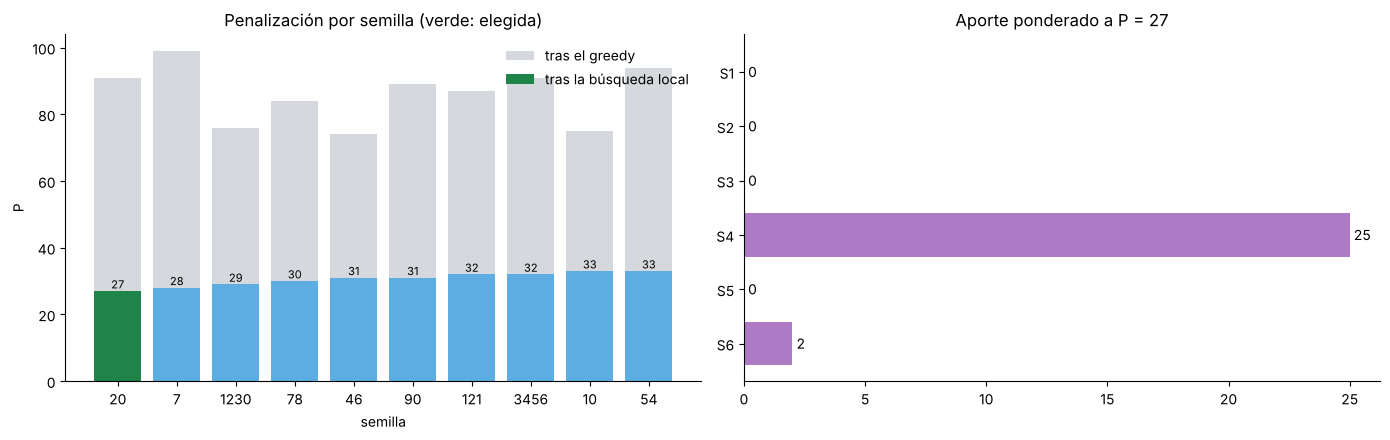

In [19]:
# =============================================================================
# V4. Penalización por semilla (verde: elegida) y aporte ponderado de S1..S6 a la mejor P
# =============================================================================
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Izquierda: P de cada semilla en el orden de la tabla comparativa, con el P del greedy de fondo.
etiquetas = [str(s) for s in tabla["seed"]]
P_greedy_de = {r["seed"]: r.get("P_greedy") for r in resultados}
colores = ["#1E8449" if s == mejor["seed"] else "#5DADE2" for s in tabla["seed"]]
ax1.bar(etiquetas, [P_greedy_de[s] for s in tabla["seed"]], color="#D5D8DC", label="tras el greedy")
barras = ax1.bar(etiquetas, tabla["P"], color=colores, label="tras la búsqueda local")
ax1.bar_label(barras, fontsize=8)
ax1.set_title("Penalización por semilla (verde: elegida)")
ax1.set_xlabel("semilla")
ax1.set_ylabel("P")
ax1.legend(frameon=False)

# Derecha: aporte ponderado de cada blanda a la P de la solución entregada.
claves = CLAVES_S[::-1]
b2 = ax2.barh(claves, [aportes[k] for k in claves], color="#AF7AC5")
ax2.bar_label(b2, padding=3)
ax2.set_title(f"Aporte ponderado a P = {mejor['P']}")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### <b style="color: #CB0000; font-size:28px;">V5. Horario interactivo en HTML</b>

La celda siguiente genera desde el código, a partir de `mejor["sol"]`, el archivo `resultados/horario.html`: es una página autocontenida (sin librerías ni conexión a internet) con los datos de la mejor solución incrustados. Con las pestañas se cambia de vista (**Semestre**, **Paquete**, **Profesor**, **Salón** o **Todo**) y con la lista se escoge cuál. Cada bloque se colorea según el tipo de salón que exige su curso, con los mismos colores del grafo de conflictos del enunciado. Las franjas de baja preferencia tienen fondo azul, las inexistentes aparecen rayadas y los bloques fuera de la franja preferida de su profesor llevan borde rojo. Al pasar el cursor sobre un bloque se ve el curso, el profesor, el salón con su capacidad, los inscritos y los paquetes. Arriba de la grilla se muestran los huecos (S1 por paquete, S2 por profesor) y los bloques que pagan S4 y S6 en la vista elegida. La misma página se muestra incrustada debajo de la celda, así que el horario se ve dentro del notebook sin abrir el archivo aparte.

In [20]:
# =============================================================================
# V5. HORARIO INTERACTIVO EN HTML  ->  resultados/horario.html
# Página autocontenida (HTML + CSS + JavaScript, sin librerías externas) generada desde `mejor`.
# Se abre con cualquier navegador y permite ver el horario por semestre, paquete, profesor o salón.
# Solo usa la biblioteca estándar (json) para incrustar los datos.
# =============================================================================
from IPython.display import HTML
from html import escape as escapar_html     # para incrustar la página en el iframe (srcdoc)

RUTA_HTML = "resultados/horario.html"
DIAS_CORTOS = {"LUNES": "Lunes", "MARTES": "Martes", "MIERCOLES": "Miércoles",
               "JUEVES": "Jueves", "VIERNES": "Viernes", "SABADO": "Sábado"}

# 1) Datos de cada bloque de la mejor solución, ya "aplanados" para el navegador.
datos_bloques = []
for a in sorted(mejor["sol"], key=lambda a: (a["id_grupo"], a["num_bloque"])):
    g, f, s = grupo[a["id_grupo"]], franja[a["id_franja"]], salon[a["id_salon"]]
    c = curso[g["id_curso"]]
    datos_bloques.append({
        "grupo": g["id_grupo"], "bloque": a["num_bloque"], "curso": c["nombre"], "semestre": c["semestre"],
        "profesor": g["id_profesor"], "salon": s["id_salon"], "capacidad": s["capacidad"],
        "tipo": c["tipo_salon"], "inscritos": g["inscritos"], "franja": f["id_franja"],
        "dia": f["dia"], "hora": f["hora_inicio"], "fin": f["hora_fin"], "pos": f["orden_dia"],
        "baja": f["baja_preferencia"], "paquetes": paquetes_de[g["id_grupo"]],
        "fuera_pref": g["id_profesor"] in tiene_pref and disp.get((g["id_profesor"], f["id_franja"])) != "PREFERIDA",
    })

datos = {
    "meta": {"equipo": EQUIPO, "instancia": inst["meta"]["id_instancia"], "seed": mejor["seed"],
             "P": mejor["P"], "factible": es_factible(mejor["H"]), "S": {k: mejor["S"].get(k, 0) for k in CLAVES_S}},
    "dias": [[d, DIAS_CORTOS.get(d, d)] for d in DIAS],
    "horas": [[h, next(f["hora_fin"] for f in inst["franjas"] if f["hora_inicio"] == h)] for h in HORAS],
    "franjas": {f"{f['dia']}|{f['hora_inicio']}": f["baja_preferencia"] for f in inst["franjas"]},
    "semestres": sorted({b["semestre"] for b in datos_bloques}),
    "paquetes": sorted(PAQ_IDS, key=lambda k: (int(k[3:].split("_")[0]), k)),
    "profesores": sorted({b["profesor"] for b in datos_bloques}),
    "salones": list(R_IDS),
    "bloques": datos_bloques,
}

# 2) Plantilla de la página. Los datos se insertan en __DATOS__ (se escapa "</" para no cerrar el <script>).
PLANTILLA_HTML = r"""<!doctype html>
<html lang="es">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Horario Ingeniería de Sistemas</title>
<style>
  :root {
    --fondo: #f6f7f9; --panel: #ffffff; --texto: #1c2430; --suave: #5d6b7a; --borde: #dde2e8;
    --rojo: #cb0000; --baja: #e3f1fa; --noexiste: #eceff2; --acento: #1e8449;
  }
  @media (prefers-color-scheme: dark) {
    :root:not([data-theme="light"]) {
      --fondo: #12161c; --panel: #1b2129; --texto: #e6eaef; --suave: #9aa7b4; --borde: #2c3540;
      --rojo: #ff5a5a; --baja: #183244; --noexiste: #232a33; --acento: #4cc38a;
    }
  }
  * { box-sizing: border-box; }
  body { margin: 0; background: var(--fondo); color: var(--texto);
         font: 14px/1.4 system-ui, -apple-system, "Segoe UI", Roboto, sans-serif; }
  header { background: var(--panel); border-bottom: 3px solid var(--rojo); padding: 16px 20px; }
  h1 { margin: 0 0 4px; font-size: 20px; color: var(--rojo); }
  .sub { color: var(--suave); font-size: 13px; }
  main { padding: 16px 20px 32px; max-width: 1500px; margin: 0 auto; }
  .controles { display: flex; flex-wrap: wrap; gap: 10px; align-items: center; margin-bottom: 12px; }
  .pestanas { display: inline-flex; border: 1px solid var(--borde); border-radius: 8px; overflow: hidden; }
  .pestanas button { border: 0; background: var(--panel); color: var(--texto); padding: 7px 12px; cursor: pointer; font: inherit; }
  .pestanas button + button { border-left: 1px solid var(--borde); }
  .pestanas button.activa { background: var(--rojo); color: #fff; }
  select { font: inherit; padding: 6px 8px; border-radius: 8px; border: 1px solid var(--borde);
           background: var(--panel); color: var(--texto); min-width: 200px; }
  .stats { display: flex; flex-wrap: wrap; gap: 8px; margin: 0 0 12px; }
  .stat { background: var(--panel); border: 1px solid var(--borde); border-radius: 8px; padding: 6px 10px; }
  .stat b { font-variant-numeric: tabular-nums; }
  .envoltura { overflow-x: auto; background: var(--panel); border: 1px solid var(--borde); border-radius: 10px; }
  table { border-collapse: collapse; width: 100%; min-width: 900px; table-layout: fixed; }
  th, td { border: 1px solid var(--borde); vertical-align: top; }
  thead th { padding: 8px; font-size: 13px; background: var(--panel); position: sticky; top: 0; }
  tbody th { width: 74px; padding: 8px 6px; font-size: 12px; text-align: center; white-space: nowrap; }
  tbody th small { display: block; color: var(--suave); font-weight: 400; }
  td { padding: 4px; height: 64px; }
  td.baja { background: var(--baja); }
  td.noexiste { background: repeating-linear-gradient(45deg, var(--noexiste), var(--noexiste) 6px, transparent 6px, transparent 12px); }
  .bloque { border-radius: 6px; padding: 4px 6px; margin: 0 0 4px; color: #1c2430; font-size: 12px;
            border-left: 4px solid rgba(0,0,0,.25); cursor: default; }
  .bloque .c { font-weight: 600; display: -webkit-box; -webkit-line-clamp: 2; -webkit-box-orient: vertical; overflow: hidden; }
  .compacto .bloque .c { display: inline; }
  .bloque .d { display: block; opacity: .85; font-size: 11px; }
  .bloque.fp { box-shadow: inset 0 0 0 2px #c0392b; }
  .compacto .bloque { display: inline-block; margin: 0 3px 3px 0; padding: 2px 5px; font-size: 11px; }
  .compacto .bloque .d { display: none; }
  .AULA { background: #f9e79f; } .LAB_COMPUTO { background: #aed6f1; } .LAB_ELECTRONICA { background: #f5cba7; }
  .LAB_REDES { background: #d2b4de; } .LAB_FISICA { background: #a3e4d7; }
  .leyenda { display: flex; flex-wrap: wrap; gap: 12px; margin-top: 12px; color: var(--suave); font-size: 12px; align-items: center; }
  .leyenda span.m { display: inline-block; width: 14px; height: 14px; border-radius: 3px; vertical-align: -2px; margin-right: 4px; }
  .vacio { color: var(--suave); padding: 24px; text-align: center; }
  @media print { header, .controles { display: none; } .envoltura { overflow: visible; border: 0; } }
</style>
</head>
<body>
<header>
  <h1>Horario del programa de Ingeniería de Sistemas</h1>
  <div class="sub" id="resumen"></div>
</header>
<main>
  <div class="controles">
    <div class="pestanas" id="pestanas">
      <button data-vista="semestre" class="activa">Semestre</button>
      <button data-vista="paquete">Paquete</button>
      <button data-vista="profesor">Profesor</button>
      <button data-vista="salon">Salón</button>
      <button data-vista="todo">Todo</button>
    </div>
    <select id="opcion" aria-label="Elemento a mostrar"></select>
  </div>
  <div class="stats" id="stats"></div>
  <div class="envoltura"><table id="grilla"></table></div>
  <div class="leyenda" id="leyenda"></div>
</main>
<script>
const D = __DATOS__;
const TIPOS = {AULA: "Aula", LAB_COMPUTO: "Lab. cómputo", LAB_ELECTRONICA: "Lab. electrónica", LAB_REDES: "Lab. redes", LAB_FISICA: "Lab. física"};
const ETIQ = {semestre: s => "Semestre " + s, paquete: k => k, profesor: p => p, salon: r => r};
let vista = "semestre";

const m = D.meta;
document.getElementById("resumen").textContent =
  `${m.equipo} · instancia ${m.instancia} · semilla ${m.seed} · P = ${m.P} · ` +
  (m.factible ? "factible (H1–H7 = 0)" : "INFACTIBLE") + " · " +
  Object.entries(m.S).map(([k, v]) => `${k}=${v}`).join("  ");

function opciones() {
  return {semestre: D.semestres, paquete: D.paquetes, profesor: D.profesores, salon: D.salones, todo: []}[vista];
}
function filtrar(v) {
  if (vista === "todo") return D.bloques;
  return D.bloques.filter(b =>
    vista === "semestre" ? b.semestre === Number(v) :
    vista === "paquete" ? b.paquetes.includes(v) :
    vista === "profesor" ? b.profesor === v : b.salon === v);
}
function huecos(bloques) {        // huecos(A) = max A − min A + 1 − |A| por día, como en el enunciado
  const porDia = {};
  bloques.forEach(b => (porDia[b.dia] = porDia[b.dia] || new Set()).add(b.pos));
  return Object.values(porDia).reduce((t, A) => {
    const p = [...A]; return t + Math.max(...p) - Math.min(...p) + 1 - p.length; }, 0);
}
function esc(t) { return String(t).replace(/[&<>"]/g, c => ({"&": "&amp;", "<": "&lt;", ">": "&gt;", '"': "&quot;"}[c])); }

function dibujar() {
  const sel = document.getElementById("opcion");
  const bl = filtrar(sel.value);
  const compacto = vista === "todo" || vista === "semestre" && bl.length > 30;
  const t = document.getElementById("grilla");
  t.className = compacto ? "compacto" : "";
  let h = "<thead><tr><th></th>" + D.dias.map(d => `<th>${d[1]}</th>`).join("") + "</tr></thead><tbody>";
  D.horas.forEach(([ini, fin]) => {
    h += `<tr><th>${ini}<small>${fin}</small></th>`;
    D.dias.forEach(([dia]) => {
      const clave = dia + "|" + ini;
      if (!(clave in D.franjas)) { h += '<td class="noexiste" title="Franja inexistente"></td>'; return; }
      const aqui = bl.filter(b => b.dia === dia && b.hora === ini);
      h += `<td class="${D.franjas[clave] ? "baja" : ""}">` + aqui.map(b => {
        const tip = `${b.curso} (${b.grupo}, bloque ${b.bloque})\nProfesor: ${b.profesor}` +
          `${b.fuera_pref ? " · fuera de su franja preferida (S4)" : ""}\nSalón: ${b.salon} (${TIPOS[b.tipo]}, capacidad ${b.capacidad}) · inscritos: ${b.inscritos}` +
          `\nFranja: ${b.franja} ${b.hora}–${b.fin}${b.baja ? " · baja preferencia (S6)" : ""}\nPaquetes: ${b.paquetes.join(", ")}`;
        return `<div class="bloque ${b.tipo}${b.fuera_pref ? " fp" : ""}" title="${esc(tip)}">` +
          `<span class="c">${esc(compacto ? b.grupo + "#" + b.bloque : b.curso)}</span>` +
          `<span class="d">${esc(b.grupo)}#${b.bloque} · ${esc(b.salon)} · ${esc(b.profesor)}</span></div>`;
      }).join("") + "</td>";
    });
    h += "</tr>";
  });
  t.innerHTML = h + "</tbody>";

  const st = [["Bloques", bl.length], ["Días usados", new Set(bl.map(b => b.dia)).size],
              ["En baja preferencia (S6)", bl.filter(b => b.baja).length],
              ["Fuera de preferida (S4)", bl.filter(b => b.fuera_pref).length]];
  if (vista === "paquete") st.splice(2, 0, ["Huecos de estudiantes (S1)", huecos(bl)]);
  if (vista === "profesor") st.splice(2, 0, ["Huecos del profesor (S2)", huecos(bl)]);
  if (vista === "salon") st.splice(1, 0, ["Ocupación", Math.round(100 * bl.length / Object.keys(D.franjas).length) + " %"]);
  document.getElementById("stats").innerHTML = st.map(([k, v]) => `<div class="stat">${k}: <b>${v}</b></div>`).join("");
}

function cambiarVista(v) {
  vista = v;
  document.querySelectorAll("#pestanas button").forEach(b => b.classList.toggle("activa", b.dataset.vista === v));
  const sel = document.getElementById("opcion");
  sel.innerHTML = opciones().map(o => `<option value="${esc(o)}">${esc(ETIQ[v](o))}</option>`).join("");
  sel.style.display = v === "todo" ? "none" : "";
  dibujar();
}
document.getElementById("pestanas").addEventListener("click", e => { if (e.target.dataset.vista) cambiarVista(e.target.dataset.vista); });
document.getElementById("opcion").addEventListener("change", dibujar);
document.getElementById("leyenda").innerHTML =
  Object.entries(TIPOS).map(([k, v]) => `<span><span class="m ${k}"></span>${v}</span>`).join("") +
  '<span><span class="m" style="background:var(--baja);border:1px solid var(--borde)"></span>Franja de baja preferencia</span>' +
  '<span><span class="m" style="box-shadow:inset 0 0 0 2px #c0392b"></span>Fuera de la franja preferida del profesor</span>' +
  '<span>Pase el cursor sobre un bloque para ver el detalle.</span>';
cambiarVista("semestre");
</script>
</body>
</html>
"""

html_horario = PLANTILLA_HTML.replace("__DATOS__", json.dumps(datos, ensure_ascii=False).replace("</", "<\\/"))
with open(RUTA_HTML, "w", encoding="utf-8") as fh:
    fh.write(html_horario)
print(f"Horario interactivo guardado en {RUTA_HTML} ({len(html_horario) / 1024:.0f} KB, {len(datos_bloques)} bloques).")
print("Ábralo con cualquier navegador; también se muestra aquí abajo, generado por esta misma celda.")
# 3) Se incrusta la misma página dentro de la salida del notebook (srcdoc): se ve sin depender del archivo.
display(HTML(f'<iframe srcdoc="{escapar_html(html_horario, quote=True)}" '
             'style="width:100%; height:760px; border:1px solid #ccc; border-radius:6px;"></iframe>'))

Horario interactivo guardado en resultados/horario.html (69 KB, 180 bloques).
Ábralo con cualquier navegador; también se muestra aquí abajo, generado por esta misma celda.


/usr/local/lib/python3.12/dist-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


**Lectura de V1 a V4.** En la grilla general casi no hay bloques en las filas azules: solo 2 de los 180 quedaron en franjas de baja preferencia, y los dos son de la electiva ELV-04-G1. En los horarios por semestre y por paquete no hay huecos; la tabla de V3 da 0 en los 20 paquetes. Los semestres 1 a 7 usan 5 días y los paquetes de 8.º a 10.º usan 6, porque comparten las electivas. En V4 las barras grises son la P que dejó el greedy (74 a 99) y las de color la P final (27 a 33). La gráfica de la derecha muestra que casi toda la penalización que queda es S4.

## <b style="color: #CB0000; font-size:28px;">Preguntas de análisis</b>

Respóndalas con datos de **sus** corridas (las respuestas van al final del notebook, sección *Respuestas*).

1. ¿Qué restricción blanda aporta más a la penalización de su mejor solución? Explique, con los datos de la instancia, por qué es difícil reducirla.
2. ¿Cuánto varía la penalización entre semillas (mejor, peor, media y desviación estándar)? ¿Qué indica esa variación sobre su método?
3. Exprese en notación Big-O el costo de `evaluar`, de la fase constructiva y de una iteración de la búsqueda local, en función de B (bloques), F (franjas) y R (salones). Contraste con un tiempo medido.
4. ¿Por qué la fase constructiva ordena los bloques del más restringido al menos restringido? ¿Qué ocurre si se ordenan al azar?

## <b style="color: #CB0000; font-size:28px;">Conclusiones</b>

Las 10 semillas dieron horarios factibles. La mejor fue la semilla 20 con P = 27 y la peor quedó en 33. Al releer `resultados/solucion_publica.json`, la verificación da la misma P y el formato queda correcto.

Lo que más pesa en la calidad es la búsqueda local. El greedy deja la penalización entre 74 y 99, y el recocido simulado la baja entre un 56 % y un 72 % según la semilla. De los movimientos, las cadenas de Kempe fueron las que más ayudaron: en pruebas previas con 2 millones de iteraciones, solo moviendo e intercambiando bloques quedábamos entre 39 y 45, y al agregar Kempe bajamos a 29–36.

Casi toda la penalización que queda es S4 (25 de 27 puntos), y los datos lo explican. Varios profesores tienen menos franjas preferidas que bloques, lo que deja un mínimo de 11 puntos que ningún horario puede evitar, y las electivas compartidas por 9 paquetes les quitan franjas a los grupos de 8.º a 10.º.

El orden del greedy cambia mucho el punto de partida, pero poco el resultado final. Con la clave `flexibilidad()` de la plantilla el greedy promedia 201.9 y con la nuestra 86.0, pero después de 300 000 iteraciones de búsqueda local los tres órdenes que probamos quedan entre 37 y 39.

Por último, calcular el costo de forma incremental fue lo que hizo viable el método. Una iteración de la búsqueda local sale unas 100 veces más barata que llamar a `evaluar`, y eso nos permitió correr 3 millones de iteraciones por semilla y terminar las 10 semillas en menos de 4 minutos, lejos del límite de 20.

## <b style="color: #CB0000; font-size:28px;">Declaración de uso de inteligencia artificial</b>

| Herramienta | Para qué se usó | Celdas / secciones |
|---|---|---|
| Claude Code (Anthropic) | Nos ayudó a escribir y depurar el código de `evaluar`, de `resolver` (máscaras de bits, cadena de Kempe, recocido simulado) y de las visualizaciones, a probar combinaciones de parámetros (temperaturas, mezcla de movimientos, iteraciones) y a redactar y corregir los textos de análisis y las respuestas, que revisamos contra las salidas del notebook. | Evaluación exacta, Pipeline por semilla, Resumen, V1–V5, Respuestas 1–4, Conclusiones |

Todo el código se ejecutó y se comprobó en este notebook: las 6 pruebas de `evaluar` dan `[OK]`, el `assert` de `resolver` revisa que el costo incremental coincida con `evaluar` y la verificación final relee el JSON entregado. Los tres integrantes revisamos cada celda para poder explicarla y modificarla en la sustentación.

## <b style="color: #CB0000; font-size:28px;">Respuestas</b>

### <b style="color: #CB0000; font-size:28px;">Respuesta 1</b>

In [21]:
# =============================================================================
# Datos para la Respuesta 1: ¿de dónde sale S4 en la mejor solución?
# Por profesor con franjas PREFERIDA: bloques que dicta, cuántas franjas preferidas tiene,
# el mínimo de S4 que tendría aunque fuera el único profesor del programa (bloques − preferidas)
# y lo que paga en la solución entregada.
# =============================================================================
paga_s4 = [a for a in mejor["sol"]
           if grupo[a["id_grupo"]]["id_profesor"] in tiene_pref
           and disp.get((grupo[a["id_grupo"]]["id_profesor"], a["id_franja"])) != "PREFERIDA"]
ocupado_en = {(a["id_franja"], a["id_salon"]) for a in mejor["sol"]}
franjas_de_paq = defaultdict(set)
for a in mejor["sol"]:
    for k in paquetes_de[a["id_grupo"]]:
        franjas_de_paq[k].add(a["id_franja"])
franjas_de_prof = defaultdict(set)
for a in mejor["sol"]:
    franjas_de_prof[grupo[a["id_grupo"]]["id_profesor"]].add(a["id_franja"])

filas_s4 = []
for p in PROF_IDS:
    if p not in tiene_pref:
        continue
    gs = [g for g in G_IDS if grupo[g]["id_profesor"] == p]
    nb = sum(grupo[g]["num_bloques"] for g in gs)
    pref = [f for f in F_IDS if disp.get((p, f)) == "PREFERIDA"]
    filas_s4.append({"profesor": p, "grupos": len(gs), "bloques": nb, "franjas PREFERIDA": len(pref),
                     "mínimo aislado": max(0, nb - len(pref)),
                     "S4 en la solución": sum(1 for a in paga_s4 if grupo[a["id_grupo"]]["id_profesor"] == p),
                     "salones": " ".join(sorted({curso[grupo[g]["id_curso"]]["tipo_salon"] for g in gs}))})
tabla_s4 = pd.DataFrame(filas_s4).set_index("profesor").sort_values("S4 en la solución", ascending=False)
display(tabla_s4[tabla_s4["S4 en la solución"] > 0])
print(f"Profesores con al menos una PREFERIDA: {len(tabla_s4)} de {len(PROF_IDS)}; "
      f"dictan {tabla_s4['bloques'].sum()} de {B} bloques y tienen en total {tabla_s4['franjas PREFERIDA'].sum()} franjas preferidas.")
print(f"S4 de la solución = {len(paga_s4)};  suma de los mínimos aislados = {tabla_s4['mínimo aislado'].sum()}")

# ¿Por qué cada bloque que paga S4 no está en una franja preferida de su profesor?
# Para cada franja preferida (y disponible) del profesor se mira qué la bloquea en la solución.
motivos = Counter()
for a in paga_s4:
    g = grupo[a["id_grupo"]]
    p = g["id_profesor"]
    for fid in F_IDS:
        if disp.get((p, fid)) != "PREFERIDA":
            continue
        if fid in franjas_de_prof[p]:
            motivos["el profesor ya dicta otro bloque ahí"] += 1
        elif any(fid in franjas_de_paq[k] for k in paquetes_de[a["id_grupo"]]):
            motivos["un paquete del grupo ya tiene clase ahí (H3)"] += 1
        elif all((fid, R_IDS[r]) in ocupado_en for r in G_SAL[GI[a["id_grupo"]]]):
            motivos["todos los salones compatibles están ocupados (H2/H4/H6)"] += 1
        else:
            motivos["libre (moverlo empeoraría otra blanda)"] += 1
print("\nQué ocupa las franjas preferidas de los bloques que pagan S4 (bloque × franja preferida):")
for m, c in motivos.most_common():
    print(f"  {c:4d}  {m}")

,grupos,bloques,franjas PREFERIDA,mínimo aislado,S4 en la solución,salones
profesor,,,,,,
P26,3,6,3,3,4,LAB_COMPUTO LAB_REDES
P23,3,6,3,3,3,AULA LAB_COMPUTO
P29,3,6,4,2,3,AULA LAB_COMPUTO LAB_REDES
P21,3,6,8,0,2,AULA LAB_COMPUTO
P05,2,6,5,1,2,LAB_FISICA
P09,2,6,7,0,2,AULA
P25,3,6,5,1,2,AULA LAB_COMPUTO
P20,3,6,5,1,1,AULA LAB_COMPUTO
P16,3,6,8,0,1,LAB_COMPUTO LAB_FISICA


Profesores con al menos una PREFERIDA: 30 de 30; dictan 180 de 180 bloques y tienen en total 229 franjas preferidas.
S4 de la solución = 25;  suma de los mínimos aislados = 11

Qué ocupa las franjas preferidas de los bloques que pagan S4 (bloque × franja preferida):
    93  el profesor ya dicta otro bloque ahí
    17  libre (moverlo empeoraría otra blanda)
    15  un paquete del grupo ya tiene clase ahí (H3)
     4  todos los salones compatibles están ocupados (H2/H4/H6)


S4, que cuenta los bloques que quedan fuera de las franjas preferidas del profesor, aporta 25 de los 27 puntos (93 %). Los otros 2 son de S6, y S1, S2, S3 y S5 quedaron en cero.

Bajarla es difícil por varias razones que se ven en la tabla de arriba. Los 30 profesores tienen franjas preferidas, así que S4 se cobra sobre los 180 bloques, y las 229 preferidas que hay en total están muy mal repartidas. Algunos profesores ni siquiera tienen preferidas suficientes para sus propios bloques: P23 y P26 dictan 6 bloques y tienen 3 preferidas, P29 tiene 4 para 6, y P05, P20 y P25 tienen 5 para 6. Aunque cada uno fuera el único profesor del programa, pagaría al menos sus bloques menos sus preferidas, y eso suma 11 puntos que ningún horario puede evitar. Nosotros pagamos 25. P23 y P20 pagan justo su mínimo (3 y 1), P26 paga 4 con mínimo 3, P29 paga 3 con mínimo 2, y P05 y P25 pagan 2 con mínimo 1.

Los otros 14 puntos salen de choques entre recursos. Para cada bloque que paga S4 miramos qué ocupa las franjas preferidas de su profesor en la solución entregada, contando pares bloque–franja. En 93 casos es otro bloque del mismo profesor, porque sus preferidas son pocas y ya las usan sus otros grupos. En 15 casos la franja la ocupa un paquete del grupo (H3). Esto pasa sobre todo en 8.º, 9.º y 10.º, donde las 6 electivas están en los 9 paquetes y bloquean esas franjas para todos a la vez. En 4 casos todos los salones compatibles están ocupados: LAB_FISICA, LAB_REDES y LAB_ELECTRONICA tienen un solo salón cada uno y P05 solo dicta en LAB_FISICA. En los 17 casos que quedan la franja está libre, pero mover el bloque allí rompe otra cosa, por ejemplo deja dos bloques del grupo el mismo día (3 puntos de S3) o abre un hueco en un paquete (2 puntos de S1).

S6 viene del mismo problema. Los 2 bloques en baja preferencia son de la electiva ELV-04-G1 (P23, en SA_12 y LU_06), que está en los 9 paquetes de 8.º a 10.º y cuyo profesor tiene 3 preferidas para 6 bloques. Sacarla de ahí cuesta más S4 o abre huecos en algún paquete.

En resumen, lo que queda de S4 no se debe a que la búsqueda pare antes de tiempo. Las preferencias de unos pocos profesores no caben en sus propias franjas preferidas, y las electivas compartidas les quitan las que podrían usar.

### <b style="color: #CB0000; font-size:28px;">Respuesta 2</b>

In [22]:
# =============================================================================
# Datos para la Respuesta 2: variación entre semillas, antes y después de la búsqueda local
# =============================================================================
P_final = [r["P"] for r in resultados if r["factible"]]
P_ini = [r["P_greedy"] for r in resultados if r["factible"]]
var = pd.DataFrame({"tras el greedy": P_ini, "tras la búsqueda local": P_final}).describe().loc[["min", "max", "mean", "std"]]
var.index = ["mejor", "peor", "media", "desviación estándar"]
display(var.round(1))
print(f"Rango final (peor − mejor): {max(P_final) - min(P_final)}  "
      f"= {(max(P_final) - min(P_final)) / statistics.mean(P_final):.0%} de la media;  "
      f"coeficiente de variación: {statistics.stdev(P_final) / statistics.mean(P_final):.1%}")
print(f"Reducción media de P por la búsqueda local: {1 - statistics.mean(P_final) / statistics.mean(P_ini):.0%}")
print(f"Semillas que empatan con la mejor P ({min(P_final)}):",
      [r["seed"] for r in resultados if r["factible"] and r["P"] == min(P_final)])

,tras el greedy,tras la búsqueda local
mejor,74.0,27.0
peor,99.0,33.0
media,86.0,30.6
desviación estándar,8.6,2.1


Rango final (peor − mejor): 6  = 20% de la media;  coeficiente de variación: 6.8%
Reducción media de P por la búsqueda local: 64%
Semillas que empatan con la mejor P (27): [20]


Con las 10 semillas, la mejor penalización final es 27 (semilla 20), la peor 33, la media 30.6 y la desviación estándar 2.1. Justo después del greedy, antes de la búsqueda local, esos mismos valores eran 74, 99, 86.0 y 8.6.

La variación final es pequeña: hay 6 puntos entre la mejor y la peor, cerca del 20 % de la media. Todas las corridas terminan en una zona parecida, con S1 y S3 en cero, S5 casi siempre en cero y S4 entre 23 y 30. Eso nos dice que el método es estable y no depende de tener suerte con la semilla. El greedy deja horarios muy distintos, pero el recocido los lleva a todos al rango de 27 a 33, así que la calidad la define la búsqueda local y no la construcción.

Aun así, cada semilla termina en un óptimo local distinto. Ningún horario se repite y cambian en qué profesores pagan S4, por eso sí vale la pena correr varias: la mejor de las 10 queda 3.6 puntos por debajo de la media. Pero agregar más semillas no parece ayudar mucho. En una prueba previa con 30 semillas ninguna bajó de 27, y con 6 y 20 millones de iteraciones por semilla los resultados siguieron entre 27 y 33. Creemos que lo que queda de P es propio de la instancia (ver la Respuesta 1) y no falta de búsqueda.

### <b style="color: #CB0000; font-size:28px;">Respuesta 3</b>

In [23]:
# =============================================================================
# Datos para la Respuesta 3: tiempos medidos para contrastar con la notación Big-O
# =============================================================================
import timeit

n_rep = 200
t_eval = timeit.timeit(lambda: evaluar(mejor["sol"]), number=n_rep) / n_rep   # una evaluación completa

t0 = time.perf_counter()
r_greedy = resolver(mejor["seed"], iteraciones_local=0)                        # solo la fase constructiva
t_greedy = time.perf_counter() - t0

t_por_semilla = TIEMPO_TOTAL / len(SEMILLAS)
t_iter = (t_por_semilla - t_greedy) / ITER_LOCAL                               # una iteración de búsqueda local

nF, nR = len(F_IDS), len(R_IDS)
print(f"B = {B} bloques,  F = {nF} franjas,  R = {nR} salones")
print(f"evaluar(sol)            : {t_eval * 1e3:8.3f} ms   (O(B))")
print(f"fase constructiva       : {t_greedy * 1e3:8.1f} ms   (O(B·F·R); B·F·R = {B * nF * nR:,} candidatos como máximo, "
      f"{sum(len(G_FRA[B_G[i]]) * len(G_SAL[B_G[i]]) for i in range(B)):,} tras filtrar por H4–H6)")
print(f"una iteración local     : {t_iter * 1e6:8.2f} µs   (O(1) por movimiento)")
print(f"evaluar / iteración     : {t_eval / t_iter:8.0f} veces")
print(f"\nSi cada iteración llamara a evaluar(), las {ITER_LOCAL:,} iteraciones de una semilla tardarían "
      f"≈ {ITER_LOCAL * t_eval / 60:.0f} min en lugar de {t_por_semilla:.0f} s.")

B = 180 bloques,  F = 40 franjas,  R = 12 salones
evaluar(sol)            :    0.586 ms   (O(B))
fase constructiva       :     19.8 ms   (O(B·F·R); B·F·R = 86,400 candidatos como máximo, 16,843 tras filtrar por H4–H6)
una iteración local     :     5.78 µs   (O(1) por movimiento)
evaluar / iteración     :      102 veces

Si cada iteración llamara a evaluar(), las 3,000,000 iteraciones de una semilla tardarían ≈ 29 min en lugar de 17 s.


`evaluar(sol)` es O(B). Recorre una vez las B asignaciones y, por cada una, hace consultas O(1) en diccionarios y actualiza los contadores de su profesor, su salón y sus paquetes, que son máximo 9. Después recorre esos contadores, que tienen a lo sumo O(B) claves, y cada llamada a `huecos(A)` revisa máximo 7 posiciones. La resta `REQUERIDOS − vistos` también es O(B).

La fase constructiva es O(B·F·R). Para cada bloque se prueban todas las franjas y salones permitidos, que son máximo F·R pares, y para cada par `puede_ir` y el costo local son O(1), porque solo consultan listas y máscaras de 7 bits precalculadas. Ordenar los grupos cuesta O(G log G), que es menor. En esta instancia el filtro de tipo, capacidad y disponibilidad deja 16 843 candidatos de los 86 400 posibles.

Una iteración de la búsqueda local es O(1). Cada movimiento toca 1 o 2 bloques (en Kempe, máximo 13) y solo se recalculan sus pares (paquete, día), (profesor, día) y (grupo, día) y su grupo, cantidades que no crecen con B, F ni R. Cuando aparece una solución mejor se copian las listas `fr` y `rm`, lo que es O(B), pero eso pasa pocas veces.

En nuestra ejecución `evaluar` tardó 0.59 ms, el greedy 20 ms y una iteración de búsqueda local 5.8 µs, unas 100 veces menos que una evaluación completa. Esa diferencia es la que permite correr 3 000 000 de iteraciones por semilla: si cada paso llamara a `evaluar`, una sola semilla tardaría unos 29 minutos en vez de 17 segundos. Los tiempos cambian según el computador, pero la proporción entre ellos coincide con el análisis, O(B) contra O(1).

### <b style="color: #CB0000; font-size:28px;">Respuesta 4</b>

In [24]:
# =============================================================================
# Datos para la Respuesta 4: experimento con el orden de la fase constructiva.
#   "paquetes"  : nuestra clave restriccion() (más paquetes primero)  <- la que usa la solución
#   "plantilla" : flexibilidad() tal como viene (len(paquetes) ascendente)
#   "azar"      : grupos barajados con la semilla
# a) Solo greedy (iteraciones_local=0) con las 10 semillas: ¿se atasca? ¿qué P deja?
# b) Greedy + búsqueda local corta (ITER_LOCAL // 10) con 5 semillas: ¿el orden importa al final?
# =============================================================================
ORDENES = ["paquetes", "plantilla", "azar"]
exp_greedy = []
for o in ORDENES:
    for s in SEMILLAS:
        r = resolver(s, iteraciones_local=0, orden_greedy=o)
        exp_greedy.append({"orden": o, "seed": s, "factible": r["factible"], "P": r["P"],
                           "atascado": r["atascado"]})
exp_greedy = pd.DataFrame(exp_greedy)
print("a) Solo la fase constructiva (10 semillas por orden):")
display(exp_greedy.groupby("orden", sort=False).agg(factibles=("factible", "sum"), P_media=("P", "mean"),
                                                    P_mejor=("P", "min"), P_peor=("P", "max")).round(1))

ITER_CORTA = ITER_LOCAL // 10
exp_local = []
for o in ORDENES:
    for s in SEMILLAS[:5]:
        r = resolver(s, iteraciones_local=ITER_CORTA, orden_greedy=o)
        exp_local.append({"orden": o, "seed": s, "P": r["P"]})
exp_local = pd.DataFrame(exp_local)
print(f"b) Greedy + {ITER_CORTA:,} iteraciones de búsqueda local (5 semillas por orden):")
display(exp_local.pivot(index="seed", columns="orden", values="P")[ORDENES]
        .pipe(lambda d: pd.concat([d, d.mean().to_frame("media").T.round(1)])))

# Posición en la que queda cada electiva (están en 9 paquetes) según el orden usado.
for o, clave in (("paquetes", RESTRICCION), ("plantilla", FLEX)):
    pos = sorted(G_IDS, key=lambda g: clave[g])
    print(f"Orden '{o}': las electivas ocupan las posiciones",
          [pos.index(g) + 1 for g in G_IDS if len(paquetes_de[g]) == 9], f"de {len(G_IDS)} grupos")

a) Solo la fase constructiva (10 semillas por orden):


,factibles,P_media,P_mejor,P_peor
orden,,,,
paquetes,10,86.0,74,99
plantilla,10,201.9,141,247
azar,10,122.3,97,142


b) Greedy + 300,000 iteraciones de búsqueda local (5 semillas por orden):


orden,paquetes,plantilla,azar
7,35.0,38.0,41.0
10,38.0,36.0,39.0
20,41.0,35.0,36.0
46,39.0,42.0,39.0
1230,41.0,36.0,39.0
media,38.8,37.4,38.8


Orden 'paquetes': las electivas ocupan las posiciones [2, 6, 4, 1, 3, 5] de 80 grupos
Orden 'plantilla': las electivas ocupan las posiciones [76, 80, 78, 75, 77, 79] de 80 grupos


El greedy no deshace decisiones. Cuando un bloque toma una franja, esa franja queda prohibida para todos los bloques con los que choca (mismo profesor o mismo paquete) y el salón queda ocupado. Si un grupo con muchos conflictos o con pocas opciones (pocas franjas de su profesor, un solo laboratorio posible) llega tarde, puede quedarse sin ninguna franja válida y el greedy se atasca. Si llega temprano, todavía tiene de dónde escoger y además se queda con las franjas más baratas. Es la misma idea que colorear primero los vértices de mayor grado de un grafo.

Para ver qué pasa con un orden al azar comparamos tres órdenes con 10 semillas (celda de arriba). Ninguno se atascó, porque con 40 franjas y 12 salones para 180 bloques siempre quedó alguna opción factible. La diferencia está en la calidad: solo con el greedy, nuestro orden (más paquetes primero) promedia 86.0, el azar 122.3 y la clave `flexibilidad()` de la plantilla 201.9.

Lo que más nos sorprendió fue que la clave de la plantilla quedara peor que el azar. El motivo está en su primer componente, `len(paquetes)`: al ordenar de menor a mayor, las 6 electivas, que están en 9 paquetes cada una, quedan en las posiciones 75 a 80 de 80. Cuando les llega el turno, los paquetes de 8.º, 9.º y 10.º ya ocuparon muchas franjas buenas, y a las electivas solo les quedan franjas que su profesor no prefiere o de baja preferencia. Al invertir ese componente quedan en las posiciones 1 a 6 y la P del greedy baja a menos de la mitad.

Después de la búsqueda local la diferencia casi desaparece: con 300 000 iteraciones los tres órdenes quedan entre 37 y 39 de media, y la variación entre semillas es mayor que la variación entre órdenes. El recocido con cadenas de Kempe corrige casi por completo un mal comienzo. En esta instancia, entonces, ordenar del más restringido al menos restringido sirve para no atascarse (aquí no pasó, pero con menos franjas o salones sí podría pasar) y para arrancar con un horario mucho mejor, lo que importaría si la búsqueda local fuera corta. La calidad final la pone la búsqueda local.